# Adaptive Multi-Agent System for Cryptocurrency Mining + Process Mining Event Log

This notebook implements an **adaptive multi-agent system (MAS)** in a simulated cryptocurrency mining environment.

The important modelling shift is that agents are **not assigned fixed strategies** such as *aggressive* or *conservative*. Instead, every agent has action preferences that are updated from experience.

The model contains:

- heterogeneous autonomous mining agents;
- stochastic coin-price movement;
- local energy grids with random price shocks;
- weighted-lottery mining rewards;
- emergent pool joining/leaving;
- simple reinforcement-style learning;
- social imitation of successful agents;
- an event log for process mining.

Conceptually:

```text
Simulated uncertain environment + adaptive autonomous agents
        ↓
Emergent behaviour: invest, pause, pool, exit, imitate, survive
        ↓
Event log
        ↓
Process mining analysis
```

The environment is simulated, but the **agent behaviour is adaptive and decentralized**.

## 1. Installation notes

Run this cell only if Mesa is not installed yet.

For local use, install the requirements from the provided `requirements_adaptive_crypto_mas.txt` file, or run:

```bash
pip install mesa pandas numpy matplotlib
```

Optional for process mining:

```bash
pip install pm4py
```

In [1]:
# Uncomment if needed:
%pip install mesa pandas numpy matplotlib
# Optional:
%pip install pm4py

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Imports

In [2]:
from __future__ import annotations

from dataclasses import dataclass
from typing import Dict, List, Optional, Tuple

import mesa
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Mesa version:", mesa.__version__)

Mesa version: 3.3.1


## 3. Helper functions

The Gini coefficient is used here to check whether mining wealth becomes concentrated over time.

In [3]:
def gini(values) -> float:
    """Return the Gini coefficient for a list/array of non-negative values."""
    arr = np.asarray(values, dtype=float)
    arr = arr[np.isfinite(arr)]
    if len(arr) == 0:
        return 0.0
    arr = arr - arr.min()
    if arr.sum() == 0:
        return 0.0
    arr = np.sort(arr)
    n = len(arr)
    index = np.arange(1, n + 1)
    return float((2 * np.sum(index * arr) / (n * np.sum(arr))) - ((n + 1) / n))


def softmax_choice(scores: Dict[str, float], rng: np.random.Generator, temperature: float = 1.0) -> str:
    """Sample an action from a softmax distribution over action scores."""
    actions = list(scores.keys())
    raw = np.array([scores[a] for a in actions], dtype=float)
    raw = raw - raw.max()
    temp = max(temperature, 1e-6)
    probs = np.exp(raw / temp)
    probs = probs / probs.sum()
    return str(rng.choice(actions, p=probs))

## 4. Model parameters

You can make the system more or less emergent by changing these parameters.

Important parameters:

- `learning_rate`: how fast agents update action preferences.
- `exploration_rate`: probability that agents try a non-obvious action.
- `imitation_rate`: probability that agents copy a successful peer.
- `price_volatility`: how unstable the coin price is.
- `energy_shock_prob`: probability that a local grid receives an energy price shock.
- `pool_fee`: fee paid when a pool wins.

In [4]:
@dataclass
class MiningParams:
    n_agents: int = 500
    cycles: int = 200
    seed: int = 42

    # Market / mining environment
    initial_coin_price: float = 1_000.0
    block_reward_coins: float = 1.0
    price_drift: float = 0.0005
    price_volatility: float = 0.055
    hardware_failure_prob: float = 0.015
    energy_shock_prob: float = 0.04
    energy_shock_multiplier_min: float = 1.5
    energy_shock_multiplier_max: float = 3.0

    # Cost and hardware scaling
    hash_purchase_cost: float = 8.0
    resale_value_fraction: float = 0.45
    cost_per_hash_factor: float = 0.025
    repair_cost_per_hash: float = 3.0
    min_hash_power: float = 1.0

    # Agent learning / bounded rationality
    learning_rate: float = 0.18
    exploration_rate: float = 0.08
    imitation_rate: float = 0.03
    irrationality_rate: float = 0.01
    decision_temperature: float = 0.85
    max_recent_profit_memory: int = 12

    # Pooling
    max_pools: int = 30
    pool_fee: float = 0.02

    # Exit rules
    bankruptcy_threshold: float = 20.0
    # Capitulation: rolling loss over the recent-profit window, as a
    # fraction of initial capital. Replaces winless-cycle counting.
    loss_tolerance_min: float = 0.02
    loss_tolerance_max: float = 0.12

## 5. Adaptive mining agent

Each agent has capital, hash power, energy grid, hardware efficiency, risk tolerance, capitulation threshold, and action values.

The action values work like a simple reinforcement-learning memory. If an action improves capital, the preference for that action increases. If it performs badly, the preference decreases.

In [5]:
class AdaptiveMiningAgent(mesa.Agent):
    """Autonomous mining entity with adaptive action preferences."""

    ACTIONS = [
        "mine", "invest", "pause", "repair", "join_pool", "leave_pool", "sell_hardware", "exit"
    ]

    def __init__(self, model: "AdaptiveMiningModel"):
        super().__init__(model)
        rng = model.rng
        p = model.params

        # Heterogeneous initial traits
        self.initial_capital = float(np.clip(rng.normal(1_000, 220), 300, 1_800))
        self.capital = self.initial_capital
        self.hash_power = float(np.clip(rng.lognormal(mean=2.2, sigma=0.45), 3, 25))
        self.hardware_efficiency = float(np.clip(rng.normal(1.0, 0.18), 0.55, 1.45))
        self.risk_tolerance = float(np.clip(rng.beta(2.2, 2.2), 0.05, 0.95))
        # Drawdown tolerance: rolling loss (over the memory window) that the
        # agent accepts before capitulating, as a fraction of initial capital.
        self.loss_tolerance = float(rng.uniform(p.loss_tolerance_min, p.loss_tolerance_max))
        self.grid = str(rng.choice(list(model.energy_grids.keys())))

        # Dynamic state
        self.status = "active"
        self.paused = False
        self.pool_id: Optional[int] = None
        self.needs_repair = False
        self.damaged_hash = 0.0
        self.last_action: Optional[str] = None
        self.previous_capital = self.capital
        self.recent_profits: List[float] = []
        self.cycles_without_profit = 0  # kept for statistics only
        self.total_rewards = 0.0
        self.total_costs = 0.0
        self.total_profit = 0.0
        self.times_won = 0
        self.times_mined = 0
        self.estimated_network_hash = None

        # Loss-streak aggregation for the event log (avoids one Lose event
        # per agent per cycle, which would dominate the process map).
        self.loss_streak_len = 0
        self.loss_streak_cost = 0.0

        # Adaptive action values. These are not fixed strategies.
        self.action_values: Dict[str, float] = {
            "mine": rng.normal(0.4, 0.2),
            "invest": rng.normal(0.15 + self.risk_tolerance, 0.25),
            "pause": rng.normal(0.05 + (1 - self.risk_tolerance) * 0.3, 0.2),
            "repair": rng.normal(0.1, 0.2),
            "join_pool": rng.normal(0.2 + (1 - self.risk_tolerance) * 0.4, 0.25),
            "leave_pool": rng.normal(0.05 + self.risk_tolerance * 0.3, 0.2),
            "sell_hardware": rng.normal(0.05 + (1 - self.risk_tolerance) * 0.2, 0.2),
            "exit": rng.normal(-0.6, 0.2),
        }

        model.log_event(self, "Initialize", reason="agent_created")

    @property
    def active(self) -> bool:
        return self.status == "active"

    def expected_cost(self) -> float:
        energy_price = self.model.energy_grids[self.grid]
        inefficiency = 1.0 / max(self.hardware_efficiency, 0.05)
        return self.hash_power * energy_price * self.model.params.cost_per_hash_factor * inefficiency

    def estimate_expected_reward(self) -> float:
        # Bounded information: agent does not know exact network hash perfectly.
        if self.estimated_network_hash is None:
            estimate = max(self.model.total_active_hash_estimate, self.hash_power)
        else:
            estimate = max(self.estimated_network_hash, self.hash_power)

        own_share = self.hash_power / estimate
        if self.pool_id is not None:
            # Pooling reduces variance, but reward is shared.
            own_share *= 0.85
        return own_share * self.model.params.block_reward_coins * self.model.coin_price

    def estimate_expected_profit(self) -> float:
        return self.estimate_expected_reward() - self.expected_cost()

    def drawdown_ratio(self) -> float:
        """Rolling loss over the recent-profit window, relative to initial capital."""
        rolling = float(np.sum(self.recent_profits)) if self.recent_profits else 0.0
        return max(0.0, -rolling) / max(self.initial_capital, 1.0)

    def exit_allowed(self) -> bool:
        """Only allow market exit when recent losses or capital pressure justify it."""
        p = self.model.params
        has_full_memory = len(self.recent_profits) >= p.max_recent_profit_memory
        sustained_negative_outlook = (
            has_full_memory
            and float(np.mean(self.recent_profits)) < 0
            and self.estimate_expected_profit() < 0
        )

        return (
            self.capital <= p.bankruptcy_threshold * 2
            or (has_full_memory and self.drawdown_ratio() >= 0.8 * self.loss_tolerance)
            or sustained_negative_outlook
        )

    def legal_actions(self) -> List[str]:
        if not self.active:
            return []
        actions = ["mine", "invest", "pause", "repair", "join_pool", "sell_hardware", "exit"]
        if self.pool_id is not None:
            actions.append("leave_pool")
            actions.remove("join_pool")
        if not self.needs_repair:
            actions.remove("repair")
        if self.capital < 60:
            actions = [a for a in actions if a in ["mine", "pause", "sell_hardware", "exit", "join_pool", "leave_pool"]]
        if not self.exit_allowed() and "exit" in actions:
            actions.remove("exit")
        return actions

    def score_actions(self) -> Dict[str, float]:
        """Combine learned action value with bounded-rational state-based pressure."""
        expected_profit = self.estimate_expected_profit()
        cash_ratio = self.capital / max(self.initial_capital, 1)
        price_momentum = self.model.price_momentum
        energy_price = self.model.energy_grids[self.grid]
        drawdown = self.drawdown_ratio()
        scores = {}

        for action in self.legal_actions():
            score = self.action_values[action]

            if action == "mine":
                score += 0.8 if expected_profit > 0 else -0.3
                score += 0.35 * price_momentum
                if self.paused:
                    score += 0.15
            elif action == "invest":
                score += 1.0 * self.risk_tolerance
                score += 0.7 if expected_profit > 0 else -0.8
                score += 0.4 * price_momentum
                score += -0.8 if cash_ratio < 0.55 else 0.0
            elif action == "pause":
                score += 0.8 if expected_profit < 0 else -0.5
                score += 0.4 if energy_price > self.model.grid_base_prices[self.grid] * 1.4 else 0.0
                score += 0.3 if cash_ratio < 0.7 else 0.0
            elif action == "repair":
                score += 1.1 if self.needs_repair else -1.0
                score += 0.3 if expected_profit > 0 else -0.1
            elif action == "join_pool":
                recent_mean = np.mean(self.recent_profits) if self.recent_profits else 0.0
                score += (1 - self.risk_tolerance) * 0.9
                score += 0.5 if recent_mean < 0 else 0.0
                score += 0.4 if self.times_mined > 4 and self.times_won == 0 else 0.0
            elif action == "leave_pool":
                score += self.risk_tolerance * 0.65
                score += 0.4 if expected_profit > 0 and price_momentum > 0 else 0.0
            elif action == "sell_hardware":
                score += 0.7 if cash_ratio < 0.45 else -0.2
                score += 0.5 if expected_profit < 0 else -0.2
            elif action == "exit":
                score += 2.2 if self.capital < self.model.params.bankruptcy_threshold * 2 else -0.7
                score += 1.1 if drawdown >= 0.8 * self.loss_tolerance else 0.0

            scores[action] = float(score)

        return scores

    def choose_action(self) -> Optional[str]:
        legal = self.legal_actions()
        if not legal:
            return None

        rng = self.model.rng
        if rng.random() < self.model.params.irrationality_rate:
            return str(rng.choice(legal))
        if rng.random() < self.model.params.exploration_rate:
            return str(rng.choice(legal))

        scores = self.score_actions()
        return softmax_choice(scores, rng, temperature=self.model.params.decision_temperature)

    def act(self) -> None:
        if not self.active:
            return

        self.previous_capital = self.capital
        action = self.choose_action()
        self.last_action = action
        if action is None:
            return

        if action == "mine":
            self.paused = False
            self.model.log_event(self, "Continue mining", reason="chosen_action")

        elif action == "invest":
            self.paused = False
            spend_fraction = 0.04 + 0.24 * self.risk_tolerance
            spend = min(self.capital * spend_fraction, self.capital - 40)
            if spend > 0:
                new_hash = (spend / self.model.params.hash_purchase_cost) * self.hardware_efficiency
                self.capital -= spend
                self.hash_power += new_hash
                self.model.log_event(self, "Invest in hash power", reason="adaptive_action", amount=spend, hash_added=new_hash)
            else:
                self.model.log_event(self, "Failed investment", reason="insufficient_capital")

        elif action == "pause":
            self.paused = True
            self.model.log_event(self, "Pause mining", reason="adaptive_action")

        elif action == "repair":
            repairable = min(self.damaged_hash, max(self.capital - 40, 0) / self.model.params.repair_cost_per_hash)
            repair_cost = repairable * self.model.params.repair_cost_per_hash
            if repairable > 0:
                self.capital -= repair_cost
                self.hash_power += repairable
                self.damaged_hash -= repairable
                self.needs_repair = self.damaged_hash > 0.1
                self.model.log_event(self, "Repair hardware", reason="adaptive_action", amount=repair_cost, hash_repaired=repairable)
            else:
                self.model.log_event(self, "Failed repair", reason="insufficient_capital")

        elif action == "join_pool":
            old_pool = self.pool_id
            self.pool_id = self.model.assign_pool(self)
            self.model.log_event(self, "Join pool", reason="variance_reduction", old_pool=old_pool, new_pool=self.pool_id)

        elif action == "leave_pool":
            old_pool = self.pool_id
            self.pool_id = None
            self.model.log_event(self, "Leave pool", reason="adaptive_action", old_pool=old_pool)

        elif action == "sell_hardware":
            sell_fraction = float(self.model.rng.uniform(0.08, 0.28))
            sold_hash = max(0.0, self.hash_power * sell_fraction)
            revenue = sold_hash * self.model.params.hash_purchase_cost * self.model.params.resale_value_fraction
            self.hash_power = max(self.model.params.min_hash_power, self.hash_power - sold_hash)
            self.capital += revenue
            self.model.log_event(self, "Sell hardware", reason="raise_cash_or_reduce_exposure", amount=revenue, hash_sold=sold_hash)

        elif action == "exit":
            self.exit_market(reason="voluntary_exit")

    def apply_hardware_failure(self) -> None:
        if not self.active:
            return
        if self.model.rng.random() < self.model.params.hardware_failure_prob:
            loss_fraction = float(self.model.rng.uniform(0.04, 0.18))
            lost_hash = self.hash_power * loss_fraction
            self.hash_power = max(self.model.params.min_hash_power, self.hash_power - lost_hash)
            self.damaged_hash += lost_hash
            self.needs_repair = True
            self.model.log_event(self, "Hardware degradation", reason="random_failure", hash_lost=lost_hash)

    def flush_loss_streak(self, reason: str = "streak_ended") -> None:
        """Log an aggregated event for a completed run of losing rounds."""
        if self.loss_streak_len > 0:
            self.model.log_event(
                self, "Losing streak", reason=reason,
                streak_length=int(self.loss_streak_len),
                streak_cost=float(self.loss_streak_cost),
            )
        self.loss_streak_len = 0
        self.loss_streak_cost = 0.0

    def update_after_profit(self, profit: float, reward: float, cost: float, won: bool) -> None:
        self.capital += reward - cost
        self.total_rewards += reward
        self.total_costs += cost
        self.total_profit += profit

        if cost > 0:
            self.times_mined += 1
        if won:
            self.times_won += 1

        self.recent_profits.append(profit)
        if len(self.recent_profits) > self.model.params.max_recent_profit_memory:
            self.recent_profits.pop(0)

        if profit <= 0:
            self.cycles_without_profit += 1
        else:
            self.cycles_without_profit = 0

        # Imperfect network estimate update.
        actual_hash = max(self.model.current_total_mining_hash, self.hash_power)
        noise = self.model.rng.normal(1.0, 0.18)
        observed = max(self.hash_power, actual_hash * noise)
        if self.estimated_network_hash is None:
            self.estimated_network_hash = observed
        else:
            self.estimated_network_hash = 0.85 * self.estimated_network_hash + 0.15 * observed

        self.learn_from_outcome(profit)

        # Exit rules: bankruptcy, or drawdown-based capitulation. The latter
        # triggers only with a full observation window, so early noise does
        # not cause immediate exits.
        if self.capital <= self.model.params.bankruptcy_threshold:
            self.exit_market(reason="bankruptcy")
        elif (
            len(self.recent_profits) >= self.model.params.max_recent_profit_memory
            and self.drawdown_ratio() >= self.loss_tolerance
        ):
            self.exit_market(reason="capitulation")

    def learn_from_outcome(self, profit: float) -> None:
        if self.last_action is None or self.last_action not in self.action_values:
            return
        scaled_reward = float(np.clip(profit / max(self.initial_capital, 1), -1.5, 1.5))
        old_value = self.action_values[self.last_action]
        lr = self.model.params.learning_rate
        self.action_values[self.last_action] = old_value + lr * (scaled_reward - old_value)

    def imitate(self) -> None:
        """Copy part of the action-value profile of a successful peer."""
        if not self.active or self.model.rng.random() >= self.model.params.imitation_rate:
            return

        candidates = [a for a in self.model.agents if a is not self and a.active and a.capital > self.capital * 1.15]
        if not candidates:
            return

        sample_size = min(10, len(candidates))
        sampled = list(self.model.rng.choice(candidates, size=sample_size, replace=False))
        mentor = max(sampled, key=lambda a: a.capital)
        blend = 0.12
        for action in self.ACTIONS:
            self.action_values[action] = (1 - blend) * self.action_values[action] + blend * mentor.action_values[action]

        self.model.log_event(self, "Imitate strategy", reason="social_learning", mentor_id=mentor.unique_id)

    def exit_market(self, reason: str) -> None:
        if not self.active:
            return
        self.flush_loss_streak(reason="exit")
        old_pool = self.pool_id
        self.status = "exited"
        self.paused = True
        self.pool_id = None
        self.model.log_event(self, "Exit market", reason=reason, old_pool=old_pool)

## 6. Adaptive mining model

The model manages the environment and interaction mechanism.

One cycle contains:

1. update coin price and energy prices;
2. apply random hardware failures;
3. let agents choose actions;
4. run a weighted-lottery mining round;
5. update learning and imitation;
6. collect model-level metrics.

In [6]:
class AdaptiveMiningModel(mesa.Model):
    """Adaptive MAS in a stochastic cryptocurrency mining environment."""

    def __init__(self, params: MiningParams = MiningParams()):
        super().__init__(seed=params.seed)
        self.params = params
        self.rng = np.random.default_rng(params.seed)
        self.coin_price = params.initial_coin_price
        self.price_history = [self.coin_price]
        self.price_momentum = 0.0
        self.event_log: List[dict] = []
        self.model_history: List[dict] = []
        self.pool_counter = 0
        self.current_total_mining_hash = 0.0
        self.total_active_hash_estimate = 1.0
        self.event_seq = 0  # intra-cycle event sequence counter

        # Local energy grids: base prices are arbitrary but heterogeneous.
        self.grid_base_prices = {
            "Grid_A_low_stable": 0.18,
            "Grid_B_medium": 0.25,
            "Grid_C_cheap_volatile": 0.15,
            "Grid_D_high_stable": 0.36,
        }
        self.energy_grids = dict(self.grid_base_prices)
        self.grid_volatility = {
            "Grid_A_low_stable": 0.03,
            "Grid_B_medium": 0.06,
            "Grid_C_cheap_volatile": 0.12,
            "Grid_D_high_stable": 0.04,
        }

        # Create agents. Mesa automatically registers agents when super().__init__(model) is called.
        for _ in range(params.n_agents):
            AdaptiveMiningAgent(self)

        self.collect_model_metrics()

    def update_environment(self) -> None:
        p = self.params
        old_price = self.coin_price
        self.coin_price *= float(np.exp(p.price_drift + p.price_volatility * self.rng.normal()))
        self.coin_price = float(np.clip(self.coin_price, 50, 50_000))
        self.price_history.append(self.coin_price)

        if len(self.price_history) >= 6:
            self.price_momentum = (self.price_history[-1] - self.price_history[-6]) / self.price_history[-6]
        else:
            self.price_momentum = (self.coin_price - old_price) / max(old_price, 1)

        for grid, base in self.grid_base_prices.items():
            vol = self.grid_volatility[grid]
            new_price = base * float(np.exp(vol * self.rng.normal()))
            if self.rng.random() < p.energy_shock_prob:
                new_price *= float(self.rng.uniform(p.energy_shock_multiplier_min, p.energy_shock_multiplier_max))
            self.energy_grids[grid] = float(np.clip(new_price, 0.05, 2.50))

        active_hash = sum(a.hash_power for a in self.agents if a.active)
        self.total_active_hash_estimate = max(active_hash, 1.0)

    def assign_pool(self, agent: AdaptiveMiningAgent) -> int:
        """Assign agent to an existing pool or create a new pool. Pools emerge from join decisions."""
        pool_members = self.get_pool_members()
        existing_pool_ids = list(pool_members.keys())

        if len(existing_pool_ids) == 0 or (len(existing_pool_ids) < self.params.max_pools and self.rng.random() < 0.25):
            self.pool_counter += 1
            return self.pool_counter

        sample_ids = list(self.rng.choice(existing_pool_ids, size=min(5, len(existing_pool_ids)), replace=False))

        def pool_score(pool_id: int) -> float:
            members = pool_members.get(pool_id, [])
            if not members:
                return 0.0
            avg_capital = np.mean([m.capital for m in members])
            total_hash = np.sum([m.hash_power for m in members])
            return float(avg_capital + 0.5 * total_hash)

        return int(max(sample_ids, key=pool_score))

    def get_pool_members(self) -> Dict[int, List[AdaptiveMiningAgent]]:
        pools: Dict[int, List[AdaptiveMiningAgent]] = {}
        for agent in self.agents:
            if agent.active and agent.pool_id is not None:
                pools.setdefault(agent.pool_id, []).append(agent)
        return pools

    def log_event(self, agent: AdaptiveMiningAgent, activity: str, reason: str = "", **extra) -> None:
        self.event_seq += 1
        row = {
            "case_id": f"Agent_{agent.unique_id}",
            "agent_id": int(agent.unique_id),
            "cycle": int(self.steps if hasattr(self, "steps") else 0),
            "seq": int(self.event_seq),
            "activity": activity,
            "reason": reason,
            "capital": float(agent.capital),
            "hash_power": float(agent.hash_power),
            "risk_tolerance": float(agent.risk_tolerance),
            "hardware_efficiency": float(agent.hardware_efficiency),
            "grid": agent.grid,
            "energy_price": float(self.energy_grids.get(agent.grid, np.nan)),
            "coin_price": float(self.coin_price),
            "pool_id": agent.pool_id,
            "status": agent.status,
            "paused": bool(agent.paused),
            "last_action": agent.last_action,
        }
        row.update(extra)
        self.event_log.append(row)

    def step(self) -> None:
        self.event_seq = 0  # reset intra-cycle ordering
        self.update_environment()

        for agent in list(self.agents):
            agent.apply_hardware_failure()

        self.agents.shuffle_do("act")
        self.run_mining_round()
        self.agents.shuffle_do("imitate")
        self.collect_model_metrics()

    def run_mining_round(self) -> None:
        p = self.params
        miners = [a for a in self.agents if a.active and not a.paused and a.hash_power > 0]
        self.current_total_mining_hash = float(sum(a.hash_power for a in miners))

        if not miners or self.current_total_mining_hash <= 0:
            return

        pool_members = self.get_pool_members()
        lottery_entities: List[Tuple[str, object, float]] = []

        solo_miners = [a for a in miners if a.pool_id is None]
        for agent in solo_miners:
            lottery_entities.append(("solo", agent, agent.hash_power))

        for pool_id, members in pool_members.items():
            active_members = [m for m in members if m in miners]
            pool_hash = float(sum(m.hash_power for m in active_members))
            if pool_hash > 0:
                lottery_entities.append(("pool", pool_id, pool_hash))

        weights = np.array([e[2] for e in lottery_entities], dtype=float)
        probabilities = weights / weights.sum()
        winner_index = int(self.rng.choice(len(lottery_entities), p=probabilities))
        winner_type, winner_obj, _ = lottery_entities[winner_index]

        gross_reward = p.block_reward_coins * self.coin_price
        rewards = {a.unique_id: 0.0 for a in miners}
        winners = set()

        if winner_type == "solo":
            winner = winner_obj
            rewards[winner.unique_id] = gross_reward
            winners.add(winner.unique_id)
        else:
            pool_id = int(winner_obj)
            members = [m for m in pool_members.get(pool_id, []) if m in miners]
            pool_hash = sum(m.hash_power for m in members)
            distributable_reward = gross_reward * (1 - p.pool_fee)
            for member in members:
                share = member.hash_power / max(pool_hash, 1e-9)
                rewards[member.unique_id] = distributable_reward * share
                winners.add(member.unique_id)

        for agent in miners:
            cost = agent.expected_cost()
            reward = rewards.get(agent.unique_id, 0.0)
            profit = reward - cost
            won = agent.unique_id in winners

            if won:
                agent.flush_loss_streak(reason="won_round")
                self.log_event(
                    agent, "Win reward", reason="weighted_lottery",
                    reward=reward, cost=cost, profit=profit,
                )
            else:
                agent.loss_streak_len += 1
                agent.loss_streak_cost += max(0.0, -profit)

            agent.update_after_profit(profit=profit, reward=reward, cost=cost, won=won)

        for agent in [a for a in self.agents if a.active and a.paused]:
            if agent.last_action == "pause":
                pseudo_reward = -agent.estimate_expected_profit() * 0.1
                agent.learn_from_outcome(pseudo_reward)

    def finalize_run(self) -> None:
        """Flush open loss streaks and add a terminal event for survivors."""
        for agent in self.agents:
            if agent.active:
                agent.flush_loss_streak(reason="end_of_simulation")
                self.log_event(agent, "End of simulation", reason="survived")

    def collect_model_metrics(self) -> None:
        active_agents = [a for a in self.agents if a.active]
        miners = [a for a in active_agents if not a.paused]
        pools = self.get_pool_members()

        row = {
            "cycle": int(self.steps if hasattr(self, "steps") else 0),
            "coin_price": float(self.coin_price),
            "active_agents": len(active_agents),
            "mining_agents": len(miners),
            "paused_agents": len([a for a in active_agents if a.paused]),
            "exited_agents": len([a for a in self.agents if not a.active]),
            "total_hash_power": float(sum(a.hash_power for a in active_agents)),
            "mining_hash_power": float(sum(a.hash_power for a in miners)),
            "mean_capital": float(np.mean([a.capital for a in active_agents])) if active_agents else 0.0,
            "median_capital": float(np.median([a.capital for a in active_agents])) if active_agents else 0.0,
            "capital_gini": gini([a.capital for a in active_agents]) if active_agents else 0.0,
            "n_pools": len(pools),
            "agents_in_pools": len([a for a in active_agents if a.pool_id is not None]),
        }
        for grid, price in self.energy_grids.items():
            row[f"energy_{grid}"] = float(price)
        self.model_history.append(row)

    def run_model(self, n_cycles: Optional[int] = None) -> None:
        cycles = self.params.cycles if n_cycles is None else n_cycles
        for _ in range(cycles):
            if len([a for a in self.agents if a.active]) == 0:
                break
            self.step()
        self.finalize_run()

    def event_log_df(self) -> pd.DataFrame:
        return pd.DataFrame(self.event_log)

    def model_history_df(self) -> pd.DataFrame:
        return pd.DataFrame(self.model_history)

    def agent_summary_df(self) -> pd.DataFrame:
        rows = []
        for a in self.agents:
            dominant_action = max(a.action_values, key=a.action_values.get)
            rows.append({
                "agent_id": a.unique_id,
                "status": a.status,
                "capital": a.capital,
                "initial_capital": a.initial_capital,
                "capital_growth": a.capital - a.initial_capital,
                "hash_power": a.hash_power,
                "risk_tolerance": a.risk_tolerance,
                "hardware_efficiency": a.hardware_efficiency,
                "grid": a.grid,
                "pool_id": a.pool_id,
                "times_mined": a.times_mined,
                "times_won": a.times_won,
                "win_rate": a.times_won / a.times_mined if a.times_mined else 0.0,
                "total_rewards": a.total_rewards,
                "total_costs": a.total_costs,
                "total_profit": a.total_profit,
                "loss_tolerance": a.loss_tolerance,
                "dominant_learned_action": dominant_action,
                **{f"Q_{k}": v for k, v in a.action_values.items()},
            })
        return pd.DataFrame(rows)

## 7. Run the model

For faster testing, start with 300-500 agents and 100-200 cycles. For your assignment, you can increase `n_agents` to 1000 if performance is acceptable.

In [7]:
params = MiningParams(
    n_agents=1000,
    cycles=100,
    seed=101,
    price_volatility = 0.60 / np.sqrt(365),
    exploration_rate=0.09,
    imitation_rate=0.035,
    hardware_failure_prob=0.015,
    energy_shock_prob=0.04,
    price_drift= np.log(2) / 365,
)

model = AdaptiveMiningModel(params)
model.run_model()

history_df = model.model_history_df()
event_log_df = model.event_log_df()
agent_df = model.agent_summary_df()

history_df.tail()

,cycle,coin_price,active_agents,mining_agents,paused_agents,exited_agents,total_hash_power,mining_hash_power,mean_capital,median_capital,capital_gini,n_pools,agents_in_pools,energy_Grid_A_low_stable,energy_Grid_B_medium,energy_Grid_C_cheap_volatile,energy_Grid_D_high_stable
96,96,1396.860285,990,823,167,10,34260.243866,28691.574526,244.200037,201.534246,0.426454,30,542,0.188812,0.277668,0.174340,0.360266
97,97,1330.060923,989,812,177,11,33736.771428,28339.075401,243.860976,202.071802,0.440493,30,536,0.175924,0.274803,0.154104,0.368882
98,98,1325.093635,989,802,187,11,33247.124584,26864.745071,243.336879,201.941322,0.439206,30,595,0.182119,0.264521,0.157173,0.366564
99,99,1328.681972,989,790,199,11,32967.007202,26535.560488,242.077220,200.956661,0.439360,30,605,0.289359,0.246052,0.137869,0.353057
100,100,1351.205970,989,799,190,11,32690.624506,27187.350039,241.101614,198.793581,0.443290,30,618,0.179967,0.267010,0.150195,0.391678


## 8. Inspect the generated event log

This is the main dataset for process mining.

Recommended process mining interpretation:

- `case_id`: one agent lifecycle;
- `activity`: action/outcome event;
- `cycle`: simulated timestamp;
- additional attributes: capital, hash power, grid, coin price, pool status, reason.

In [8]:
event_log_df.head(20)

,case_id,agent_id,cycle,seq,activity,reason,capital,hash_power,risk_tolerance,hardware_efficiency,...,old_pool,new_pool,hash_sold,hash_repaired,reward,cost,profit,mentor_id,streak_length,streak_cost
0,Agent_1,1,0,1,Initialize,agent_created,826.166450,3.612567,0.560478,1.108594,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Agent_2,2,0,2,Initialize,agent_created,1361.560117,7.744189,0.448784,0.782631,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Agent_3,3,0,3,Initialize,agent_created,1064.883491,6.332780,0.417985,1.235717,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Agent_4,4,0,4,Initialize,agent_created,1320.846441,23.667492,0.623835,1.093763,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Agent_5,5,0,5,Initialize,agent_created,945.324313,7.826959,0.214373,0.948686,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,Agent_6,6,0,6,Initialize,agent_created,1293.327048,8.735893,0.054865,0.550000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,Agent_7,7,0,7,Initialize,agent_created,726.449613,5.281061,0.242082,0.924696,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,Agent_8,8,0,8,Initialize,agent_created,1244.077635,3.000000,0.406284,0.698706,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,Agent_9,9,0,9,Initialize,agent_created,917.635147,10.534954,0.187834,1.164467,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,Agent_10,10,0,10,Initialize,agent_created,885.736926,8.375177,0.415698,1.044763,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
event_log_df["activity"].value_counts()

activity
Continue mining         27192
Invest in hash power    21124
Sell hardware           15512
Join pool               12369
Leave pool              11744
Pause mining             9937
Losing streak            3946
Imitate strategy         3464
Win reward               3161
Hardware degradation     1540
Repair hardware          1456
Initialize               1000
End of simulation         989
Exit market                11
Name: count, dtype: int64

## 9. Model-level behaviour over time

These plots help check whether system-level behaviour emerged:

- active agents decline when agents exit;
- pool participation may increase if mining individually is too risky;
- Gini coefficient shows concentration of capital;
- coin price and hash power show feedback between environment and agent investment.

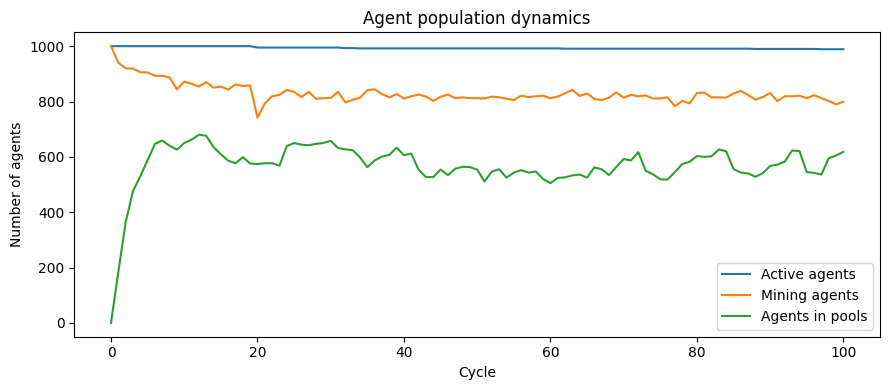

In [10]:
plt.figure(figsize=(9, 4))
plt.plot(history_df["cycle"], history_df["active_agents"], label="Active agents")
plt.plot(history_df["cycle"], history_df["mining_agents"], label="Mining agents")
plt.plot(history_df["cycle"], history_df["agents_in_pools"], label="Agents in pools")
plt.xlabel("Cycle")
plt.ylabel("Number of agents")
plt.title("Agent population dynamics")
plt.legend()
plt.tight_layout()
plt.show()

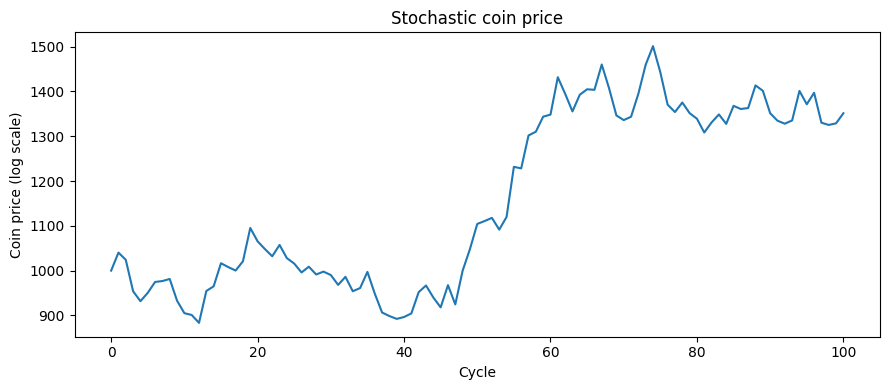

In [11]:
plt.figure(figsize=(9, 4))
plt.plot(history_df["cycle"], history_df["coin_price"])
#plt.yscale()
plt.xlabel("Cycle")
plt.ylabel("Coin price (log scale)")
plt.title("Stochastic coin price")
plt.tight_layout()
plt.show()




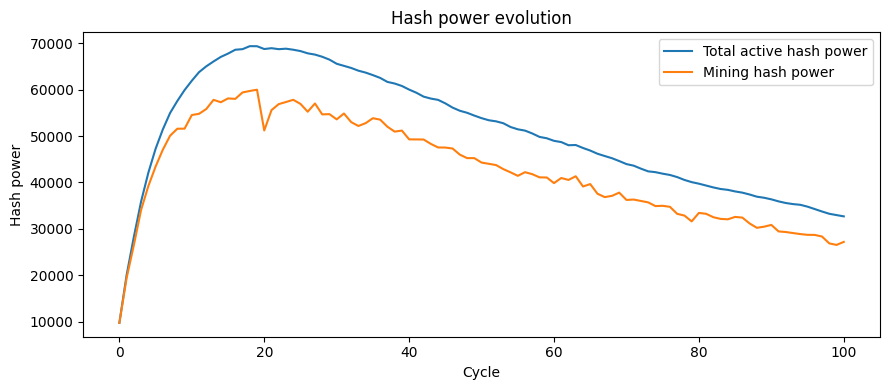

In [12]:
plt.figure(figsize=(9, 4))
plt.plot(history_df["cycle"], history_df["total_hash_power"], label="Total active hash power")
plt.plot(history_df["cycle"], history_df["mining_hash_power"], label="Mining hash power")
plt.xlabel("Cycle")
plt.ylabel("Hash power")
plt.title("Hash power evolution")
plt.legend()
plt.tight_layout()
plt.show()

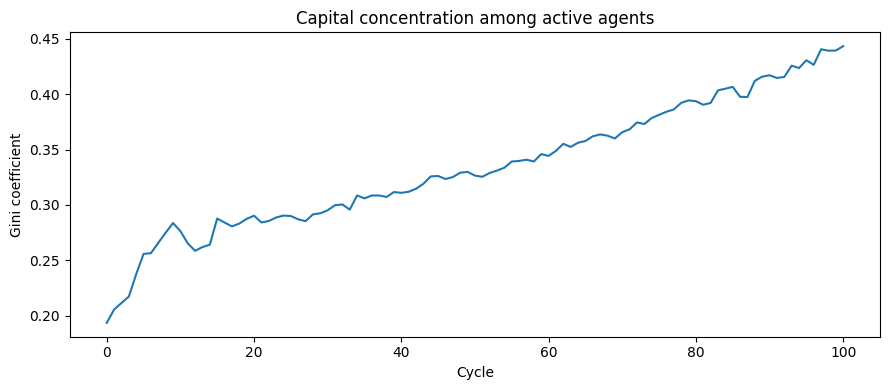

In [13]:
plt.figure(figsize=(9, 4))
plt.plot(history_df["cycle"], history_df["capital_gini"])
plt.xlabel("Cycle")
plt.ylabel("Gini coefficient")
plt.title("Capital concentration among active agents")
plt.tight_layout()
plt.show()

## 10. Agent outcomes

This section checks what kinds of agents survived, exited, or learned specific dominant actions.

In [14]:
agent_df.head()

,agent_id,status,capital,initial_capital,capital_growth,hash_power,risk_tolerance,hardware_efficiency,grid,pool_id,...,loss_tolerance,dominant_learned_action,Q_mine,Q_invest,Q_pause,Q_repair,Q_join_pool,Q_leave_pool,Q_sell_hardware,Q_exit
0,1,active,156.085352,826.166450,-670.081098,37.806823,0.560478,1.108594,Grid_A_low_stable,70.0,...,0.056414,join_pool,0.011072,0.031478,0.041578,-0.100924,0.052304,0.029766,-0.010465,-0.616519
1,2,active,210.415980,1361.560117,-1151.144136,68.355366,0.448784,0.782631,Grid_D_high_stable,NaN,...,0.104096,repair,0.001582,0.017627,0.024099,0.251350,0.057019,0.001010,-0.019556,-0.777463
2,3,active,393.628252,1064.883491,-671.255238,23.713133,0.417985,1.235717,Grid_A_low_stable,27.0,...,0.066204,join_pool,0.020791,0.026166,0.022291,-0.105188,0.047899,0.010369,0.005234,-0.470204
3,4,active,299.263028,1320.846441,-1021.583413,28.472298,0.623835,1.093763,Grid_A_low_stable,15.0,...,0.024738,repair,0.002299,0.015278,0.000012,0.156914,0.076048,0.028303,0.016657,-0.709633
4,5,active,339.388928,945.324313,-605.935385,19.374333,0.214373,0.948686,Grid_D_high_stable,NaN,...,0.094692,repair,0.011352,0.004989,0.014350,0.172119,0.042151,0.018210,0.009486,-0.519067


In [15]:
summary_by_status = agent_df.groupby("status").agg(
    agents=("agent_id", "count"),
    mean_capital=("capital", "mean"),
    median_capital=("capital", "median"),
    mean_risk=("risk_tolerance", "mean"),
    mean_hash=("hash_power", "mean"),
    mean_profit=("total_profit", "mean"),
).reset_index()

summary_by_status

,status,agents,mean_capital,median_capital,mean_risk,mean_hash,mean_profit
0,active,989,241.101614,198.793581,0.503782,33.054221,88.267571
1,exited,11,216.745137,271.574434,0.710102,79.696419,83.935079


In [16]:
learned_actions = agent_df["dominant_learned_action"].value_counts().rename_axis("dominant_action").reset_index(name="n_agents")
learned_actions

,dominant_action,n_agents
0,repair,479
1,join_pool,320
2,pause,94
3,leave_pool,72
4,sell_hardware,25
5,mine,6
6,invest,4


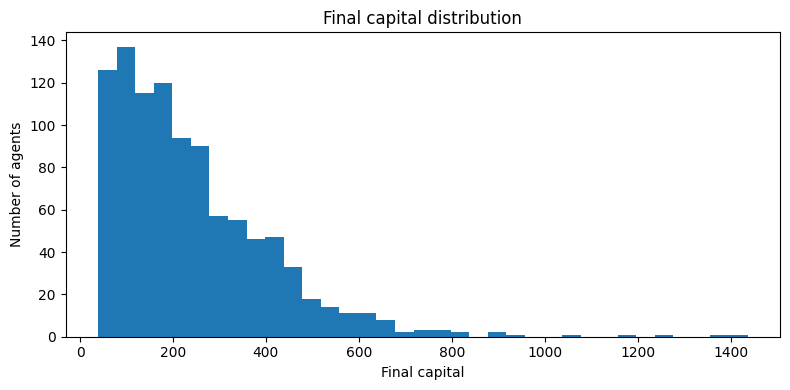

In [17]:
plt.figure(figsize=(8, 4))
plt.hist(agent_df["capital"], bins=35)
plt.xlabel("Final capital")
plt.ylabel("Number of agents")
plt.title("Final capital distribution")
plt.tight_layout()
plt.show()

## 11. Simple process mining preparation

This creates a process mining event log where:

- one case = one agent;
- each event = one action or outcome;
- timestamp = simulated cycle, converted to an artificial timestamp.

The event log can be exported to CSV.

In [18]:
# Process mining preparation for Disco:
# - tie-free timestamps from (cycle, seq): cycle -> days, seq -> seconds
# - episode-based case notion: a new episode starts at each pool join/leave,
#   so traces stay short and variant analysis remains usable
# - plain column names (Disco lets you map columns on import)

pm_log = event_log_df.copy()
pm_log = pm_log.sort_values(["agent_id", "cycle", "seq"]).reset_index(drop=True)

pm_log["timestamp"] = (
    pd.Timestamp("2026-01-01")
    + pd.to_timedelta(pm_log["cycle"], unit="D")
    + pd.to_timedelta(pm_log["seq"], unit="s")
)

EPISODE_BOUNDARIES = {"Join pool", "Leave pool"}

pm_log["episode"] = 0
for agent_id, group in pm_log.groupby("agent_id"):
    # The boundary event itself becomes the first event of the new episode.
    pm_log.loc[group.index, "episode"] = group["activity"].isin(EPISODE_BOUNDARIES).cumsum()

pm_log["case_id"] = (
    "Agent_" + pm_log["agent_id"].astype(str)
    + "_ep" + pm_log["episode"].astype(str).str.zfill(2)
)

pm_log[["case_id", "activity", "timestamp", "capital", "hash_power", "grid", "pool_id", "reason", "status"]].head(20)

,case_id,activity,timestamp,capital,hash_power,grid,pool_id,reason,status
0,Agent_1_ep00,Initialize,2026-01-01 00:00:01,826.166450,3.612567,Grid_A_low_stable,NaN,agent_created,active
1,Agent_1_ep01,Join pool,2026-01-02 00:07:12,826.166450,3.612567,Grid_A_low_stable,19.0,variance_reduction,active
2,Agent_1_ep01,Invest in hash power,2026-01-03 00:15:35,681.976231,23.591603,Grid_A_low_stable,19.0,adaptive_action,active
3,Agent_1_ep01,Continue mining,2026-01-04 00:06:15,681.879568,23.591603,Grid_A_low_stable,19.0,chosen_action,active
4,Agent_1_ep01,Continue mining,2026-01-05 00:10:14,681.783071,23.591603,Grid_A_low_stable,19.0,chosen_action,active
5,Agent_1_ep01,Continue mining,2026-01-06 00:10:42,681.688779,23.591603,Grid_A_low_stable,19.0,chosen_action,active
6,Agent_1_ep01,Invest in hash power,2026-01-07 00:07:39,562.644515,40.074722,Grid_A_low_stable,19.0,adaptive_action,active
7,Agent_1_ep01,Invest in hash power,2026-01-08 00:10:01,464.314188,53.677175,Grid_A_low_stable,19.0,adaptive_action,active
8,Agent_1_ep01,Continue mining,2026-01-09 00:03:31,464.090551,53.677175,Grid_A_low_stable,19.0,chosen_action,active
9,Agent_1_ep02,Leave pool,2026-01-10 00:04:53,463.872956,53.677175,Grid_A_low_stable,NaN,adaptive_action,active


In [19]:
# Export for process mining tools
pm_log.to_csv("output_mas/adaptive_crypto_mining_event_log.csv", index=False)
history_df.to_csv("output_mas/adaptive_crypto_mining_model_history.csv", index=False)
agent_df.to_csv("output_mas/adaptive_crypto_mining_agent_summary.csv", index=False)

print("Exported:")
print("- adaptive_crypto_mining_event_log.csv")
print("- adaptive_crypto_mining_model_history.csv")
print("- adaptive_crypto_mining_agent_summary.csv")

Exported:
- adaptive_crypto_mining_event_log.csv
- adaptive_crypto_mining_model_history.csv
- adaptive_crypto_mining_agent_summary.csv


## 12. Directly-follows analysis without PM4Py

This quick analysis gives a first process-mining-style view without installing extra packages.

In [20]:
def directly_follows_table(log: pd.DataFrame, case_col="case_id", act_col="activity") -> pd.DataFrame:
    rows = []
    for case_id, group in log.sort_values([case_col, "timestamp"]).groupby(case_col):
        activities = group[act_col].tolist()
        for a, b in zip(activities, activities[1:]):
            rows.append((a, b))
    return (
        pd.DataFrame(rows, columns=["from_activity", "to_activity"])
        .value_counts()
        .reset_index(name="frequency")
        .sort_values("frequency", ascending=False)
    )

dfg = directly_follows_table(pm_log)
dfg.head(25)

,from_activity,to_activity,frequency
0,Continue mining,Continue mining,6626
1,Continue mining,Invest in hash power,5173
2,Invest in hash power,Continue mining,5130
3,Invest in hash power,Invest in hash power,4297
4,Sell hardware,Continue mining,3965
5,Continue mining,Sell hardware,3885
6,Join pool,Continue mining,3154
7,Invest in hash power,Sell hardware,3011
8,Losing streak,Win reward,2957
9,Pause mining,Continue mining,2871


In [21]:
def variant_table(log: pd.DataFrame, max_events_per_case: int = 40) -> pd.DataFrame:
    variants = []
    for case_id, group in log.sort_values(["case_id", "timestamp"]).groupby("case_id"):
        acts = group["activity"].tolist()[:max_events_per_case]
        variants.append(" → ".join(acts))
    return pd.Series(variants).value_counts().rename_axis("variant").reset_index(name="frequency")

variants = variant_table(pm_log, max_events_per_case=25)
variants.head(10)

,variant,frequency
0,Leave pool,3544
1,Join pool,2298
2,Leave pool → Continue mining,813
3,Join pool → Continue mining,622
4,Leave pool → Invest in hash power,608
5,Join pool → Invest in hash power,455
6,Leave pool → Sell hardware,427
7,Join pool → Sell hardware,326
8,Leave pool → Pause mining,290
9,Join pool → Pause mining,205


In [22]:
import shutil

print(shutil.which("dot"))

C:\Program Files\Graphviz\bin\dot.EXE


In [23]:
import pm4py

# 1. Format the dataframe to be compatible with pm4py
pm4py_log = pm4py.format_dataframe(
    pm_log, 
    case_id='case_id', 
    activity_key='activity', 
    timestamp_key='timestamp'
)

# 2. Filter out spam/low-value activities (adjust this list based on your needs)
activities_to_remove = ["Continue mining"]
clean_log = pm4py.filter_event_attribute_values(
    pm4py_log, 
    "concept:name", 
    activities_to_remove, 
    level="event", 
    retain=False
)

print(f"Original log size: {len(pm4py_log)} events")
print(f"Cleaned log size: {len(clean_log)} events")

Original log size: 113445 events
Cleaned log size: 86253 events


C:\Users\marti\AppData\Roaming\Python\Python311\site-packages\pm4py\algo\discovery\dfg\adapters\pandas\df_statistics.py:93: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[start_timestamp_key] = df[timestamp_key]


Displaying Filtered Frequency DFG (Strong paths only)...


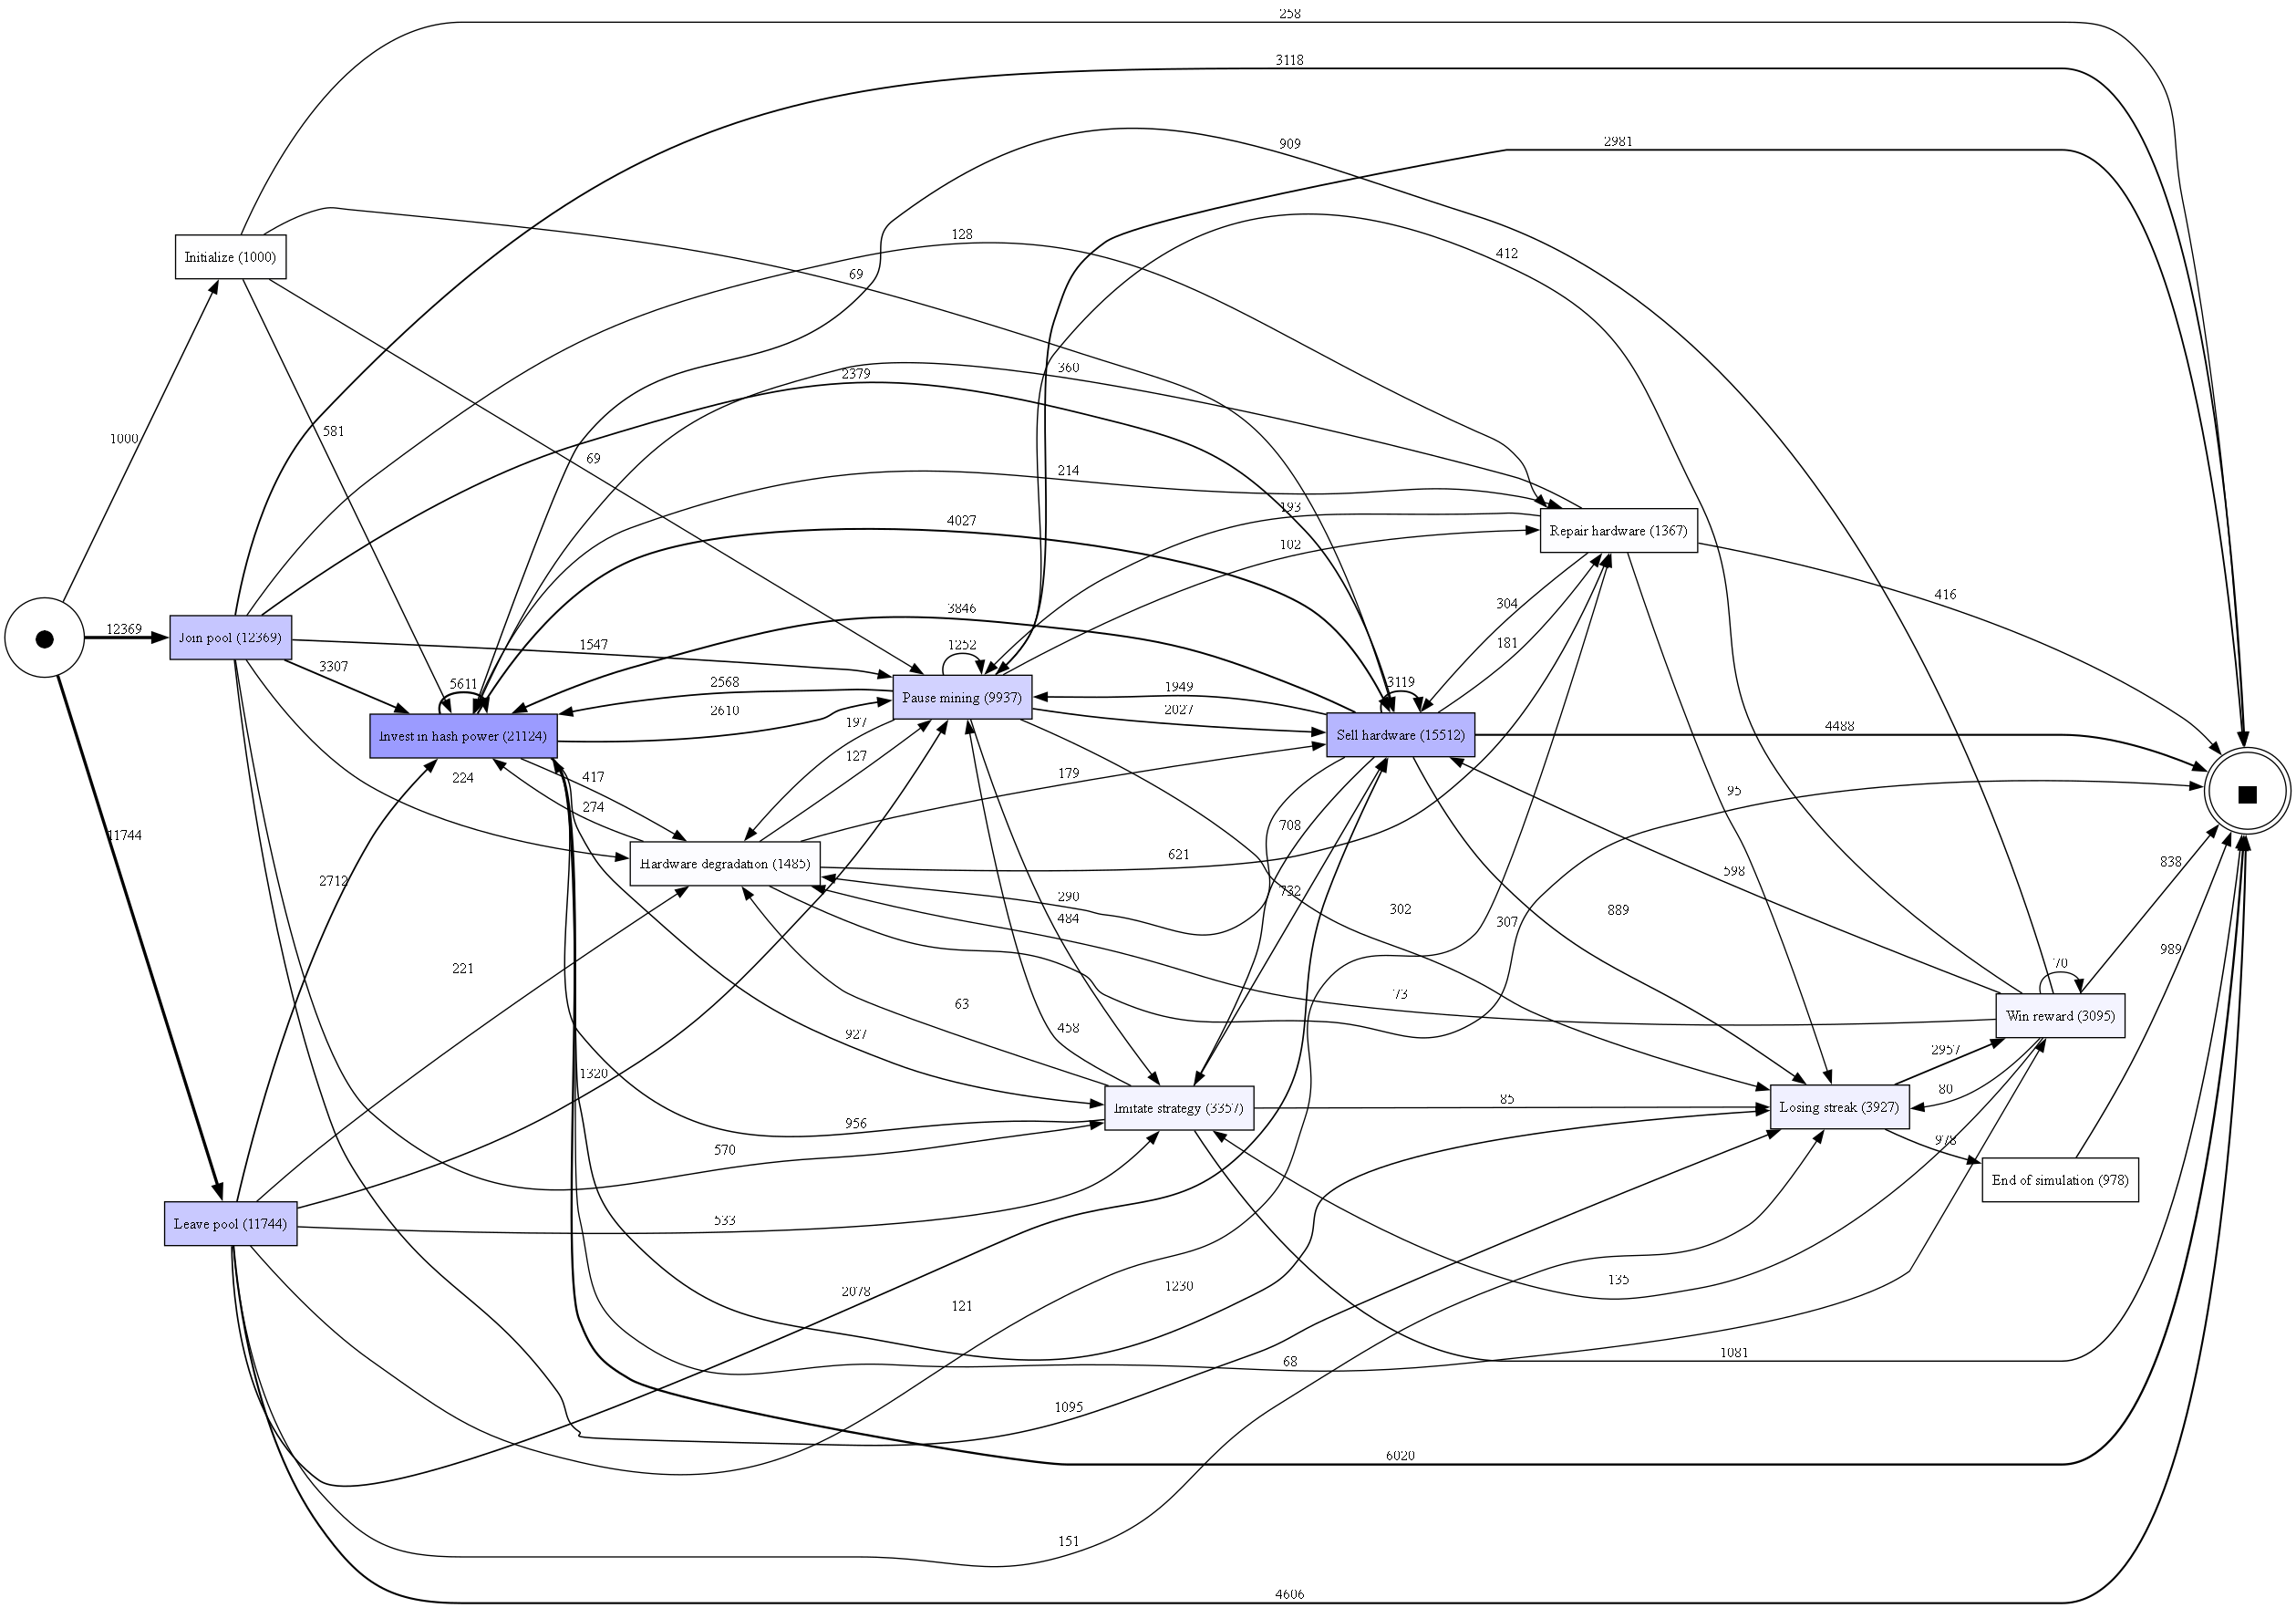

In [24]:
import pm4py

# 1. Discover the DFG on the cleaned log
dfg, start_activities, end_activities = pm4py.discover_dfg(clean_log)

# 2. EDGE FILTERING: Only keep paths that happen more than 50 times
dfg_filtered = {k: v for k, v in dfg.items() if v > 50}

# 3. SAFETY CHECK: Find all nodes that actually survived the edge filter
surviving_nodes = set([node for path in dfg_filtered.keys() for node in path])

# 4. Sync start/end activities so pm4py doesn't look for missing nodes
start_filtered = {k: v for k, v in start_activities.items() if k in surviving_nodes}
end_filtered = {k: v for k, v in end_activities.items() if k in surviving_nodes}

# 5. View the cleaned-up overview
print("Displaying Filtered Frequency DFG (Strong paths only)...")
pm4py.view_dfg(dfg_filtered, start_filtered, end_filtered)

Displaying 'Happy Path' Petri Net...


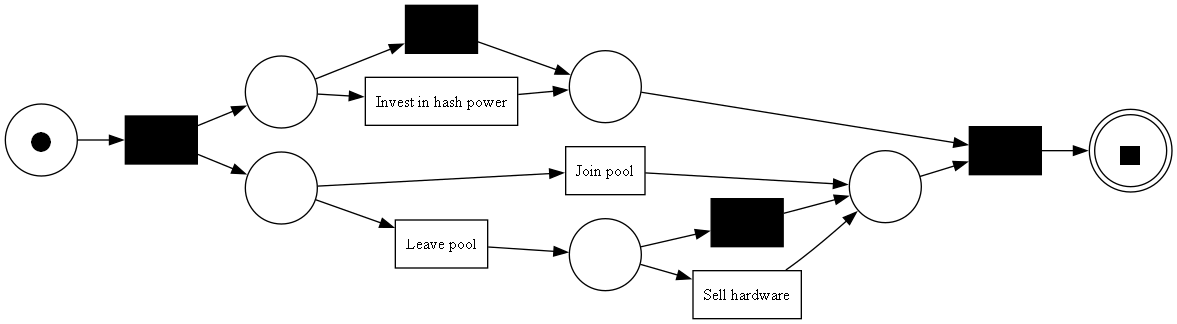

In [25]:
# 1. Filter down to the absolute most common sequences (Top 5 variants)
happy_path_log = pm4py.filter_variants_top_k(clean_log, 5) 

# 2. Discover a Petri Net using the Inductive Miner on ONLY the happy path
net, initial_marking, final_marking = pm4py.discover_petri_net_inductive(happy_path_log)

# 3. View the structurally sound, highly readable Petri Net
print("Displaying 'Happy Path' Petri Net...")
pm4py.view_petri_net(net, initial_marking, final_marking)

Displaying 'Happy Path' BPMN Model...


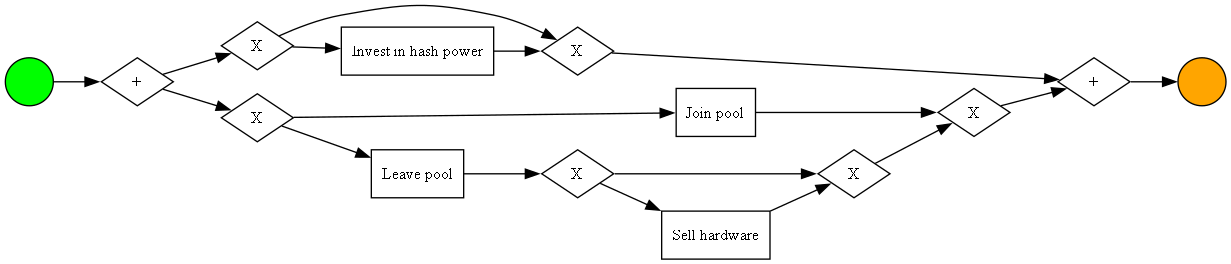

In [26]:
# Discover a BPMN model using the same isolated happy path data
bpmn_model = pm4py.discover_bpmn_inductive(happy_path_log)

# View the BPMN model
print("Displaying 'Happy Path' BPMN Model...")
pm4py.view_bpmn(bpmn_model)

--- TOP 10 PATHS (SURVIVORS) ---
Losing streak -> End of simulation: 978
Sell hardware -> Losing streak: 274
Invest in hash power -> Losing streak: 247
Sell hardware -> Sell hardware: 235
Sell hardware -> Invest in hash power: 226
Invest in hash power -> Sell hardware: 219
Join pool -> Losing streak: 187
Invest in hash power -> Invest in hash power: 180
Join pool -> Sell hardware: 157
Pause mining -> Losing streak: 157

--- TOP 10 PATHS (LOSERS) ---
Losing streak -> Exit market: 11
Invest in hash power -> Invest in hash power: 4
Sell hardware -> Losing streak: 4
Invest in hash power -> Imitate strategy: 3
Invest in hash power -> Sell hardware: 3
Join pool -> Invest in hash power: 3
Join pool -> Losing streak: 3
Sell hardware -> Invest in hash power: 3
Hardware degradation -> Repair hardware: 2
Invest in hash power -> Pause mining: 2


Displaying 'Exit Market' DFG (Edges > 2)...


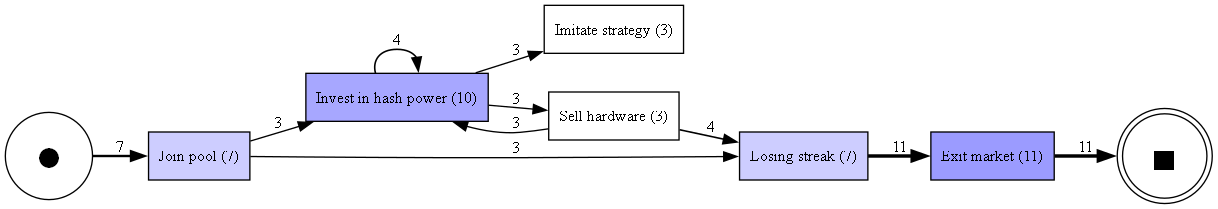

Displaying 'End of Simulation' DFG (Edges > 50)...


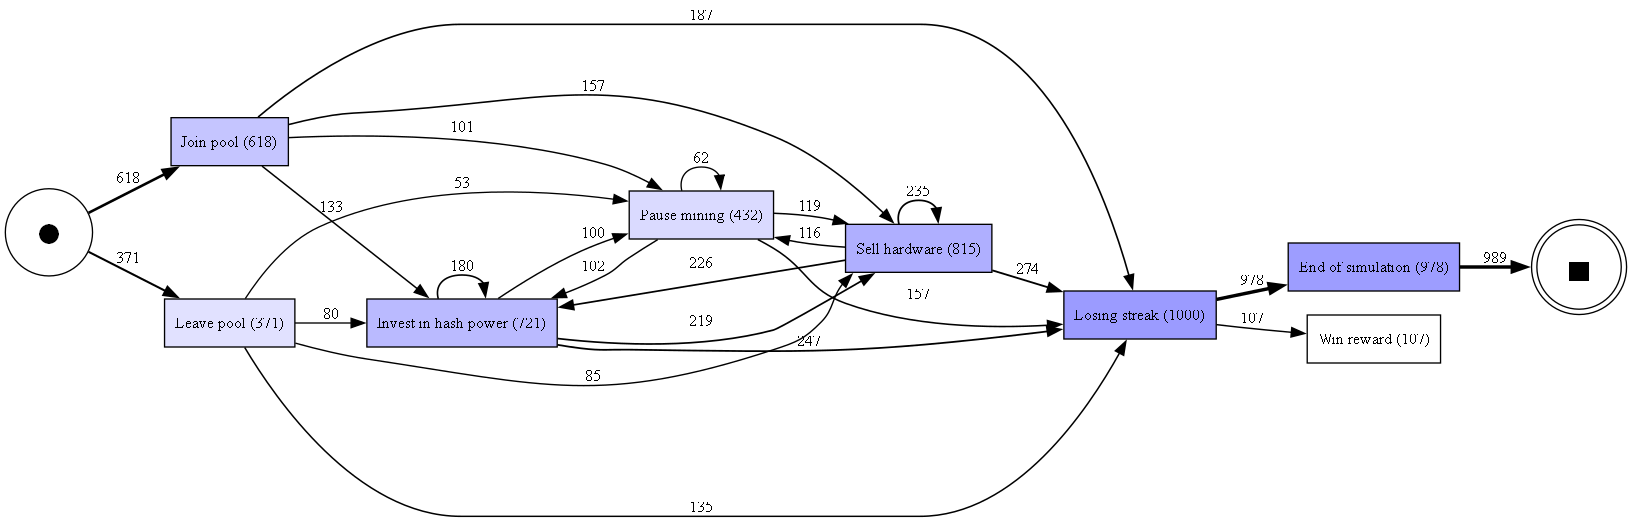

In [27]:
from collections import Counter

# 1. Split the log based on the final outcome of the case
losers_log = pm4py.filter_end_activities(clean_log, ["Exit market"])
survivors_log = pm4py.filter_end_activities(clean_log, ["End of simulation"])

# 2. Discover raw DFGs for both segments
dfg_losers, start_l, end_l = pm4py.discover_dfg(losers_log)
dfg_survivors, start_s, end_s = pm4py.discover_dfg(survivors_log)

# --- DIAGNOSTICS: Let's see the actual numbers! ---
print("--- TOP 10 PATHS (SURVIVORS) ---")
for path, count in Counter(dfg_survivors).most_common(10):
    print(f"{path[0]} -> {path[1]}: {count}")

print("\n--- TOP 10 PATHS (LOSERS) ---")
for path, count in Counter(dfg_losers).most_common(10):
    print(f"{path[0]} -> {path[1]}: {count}")
print("\n")

# --- THE FIX: MUCH LOWER THRESHOLDS ---
# Dropping this down so we catch the middle loops
THRESHOLD_LOSERS = 2 
THRESHOLD_SURVIVORS = 50 

# Filter the "Losers" DFG
dfg_l_filtered = {k: v for k, v in dfg_losers.items() if v > THRESHOLD_LOSERS}
surviving_l_nodes = set([node for path in dfg_l_filtered.keys() for node in path])
start_l_filt = {k: v for k, v in start_l.items() if k in surviving_l_nodes}
end_l_filt = {k: v for k, v in end_l.items() if k in surviving_l_nodes}

# Filter the "Survivors" DFG
dfg_s_filtered = {k: v for k, v in dfg_survivors.items() if v > THRESHOLD_SURVIVORS}
surviving_s_nodes = set([node for path in dfg_s_filtered.keys() for node in path])
start_s_filt = {k: v for k, v in start_s.items() if k in surviving_s_nodes}
end_s_filt = {k: v for k, v in end_s.items() if k in surviving_s_nodes}
# ------------------------------------------

# 3. View the 'Exit Market' (Failure) graph
if len(dfg_l_filtered) == 0:
    print(f"⚠️ THRESHOLD ERROR: {THRESHOLD_LOSERS} is too high for Losers. Lower it.")
else:
    print(f"Displaying 'Exit Market' DFG (Edges > {THRESHOLD_LOSERS})...")
    pm4py.view_dfg(dfg_l_filtered, start_l_filt, end_l_filt)

# 4. View the 'End of Simulation' (Success) graph
if len(dfg_s_filtered) == 0:
    print(f"⚠️ THRESHOLD ERROR: {THRESHOLD_SURVIVORS} is too high for Survivors. Lower it.")
else:
    print(f"Displaying 'End of Simulation' DFG (Edges > {THRESHOLD_SURVIVORS})...")
    pm4py.view_dfg(dfg_s_filtered, start_s_filt, end_s_filt)

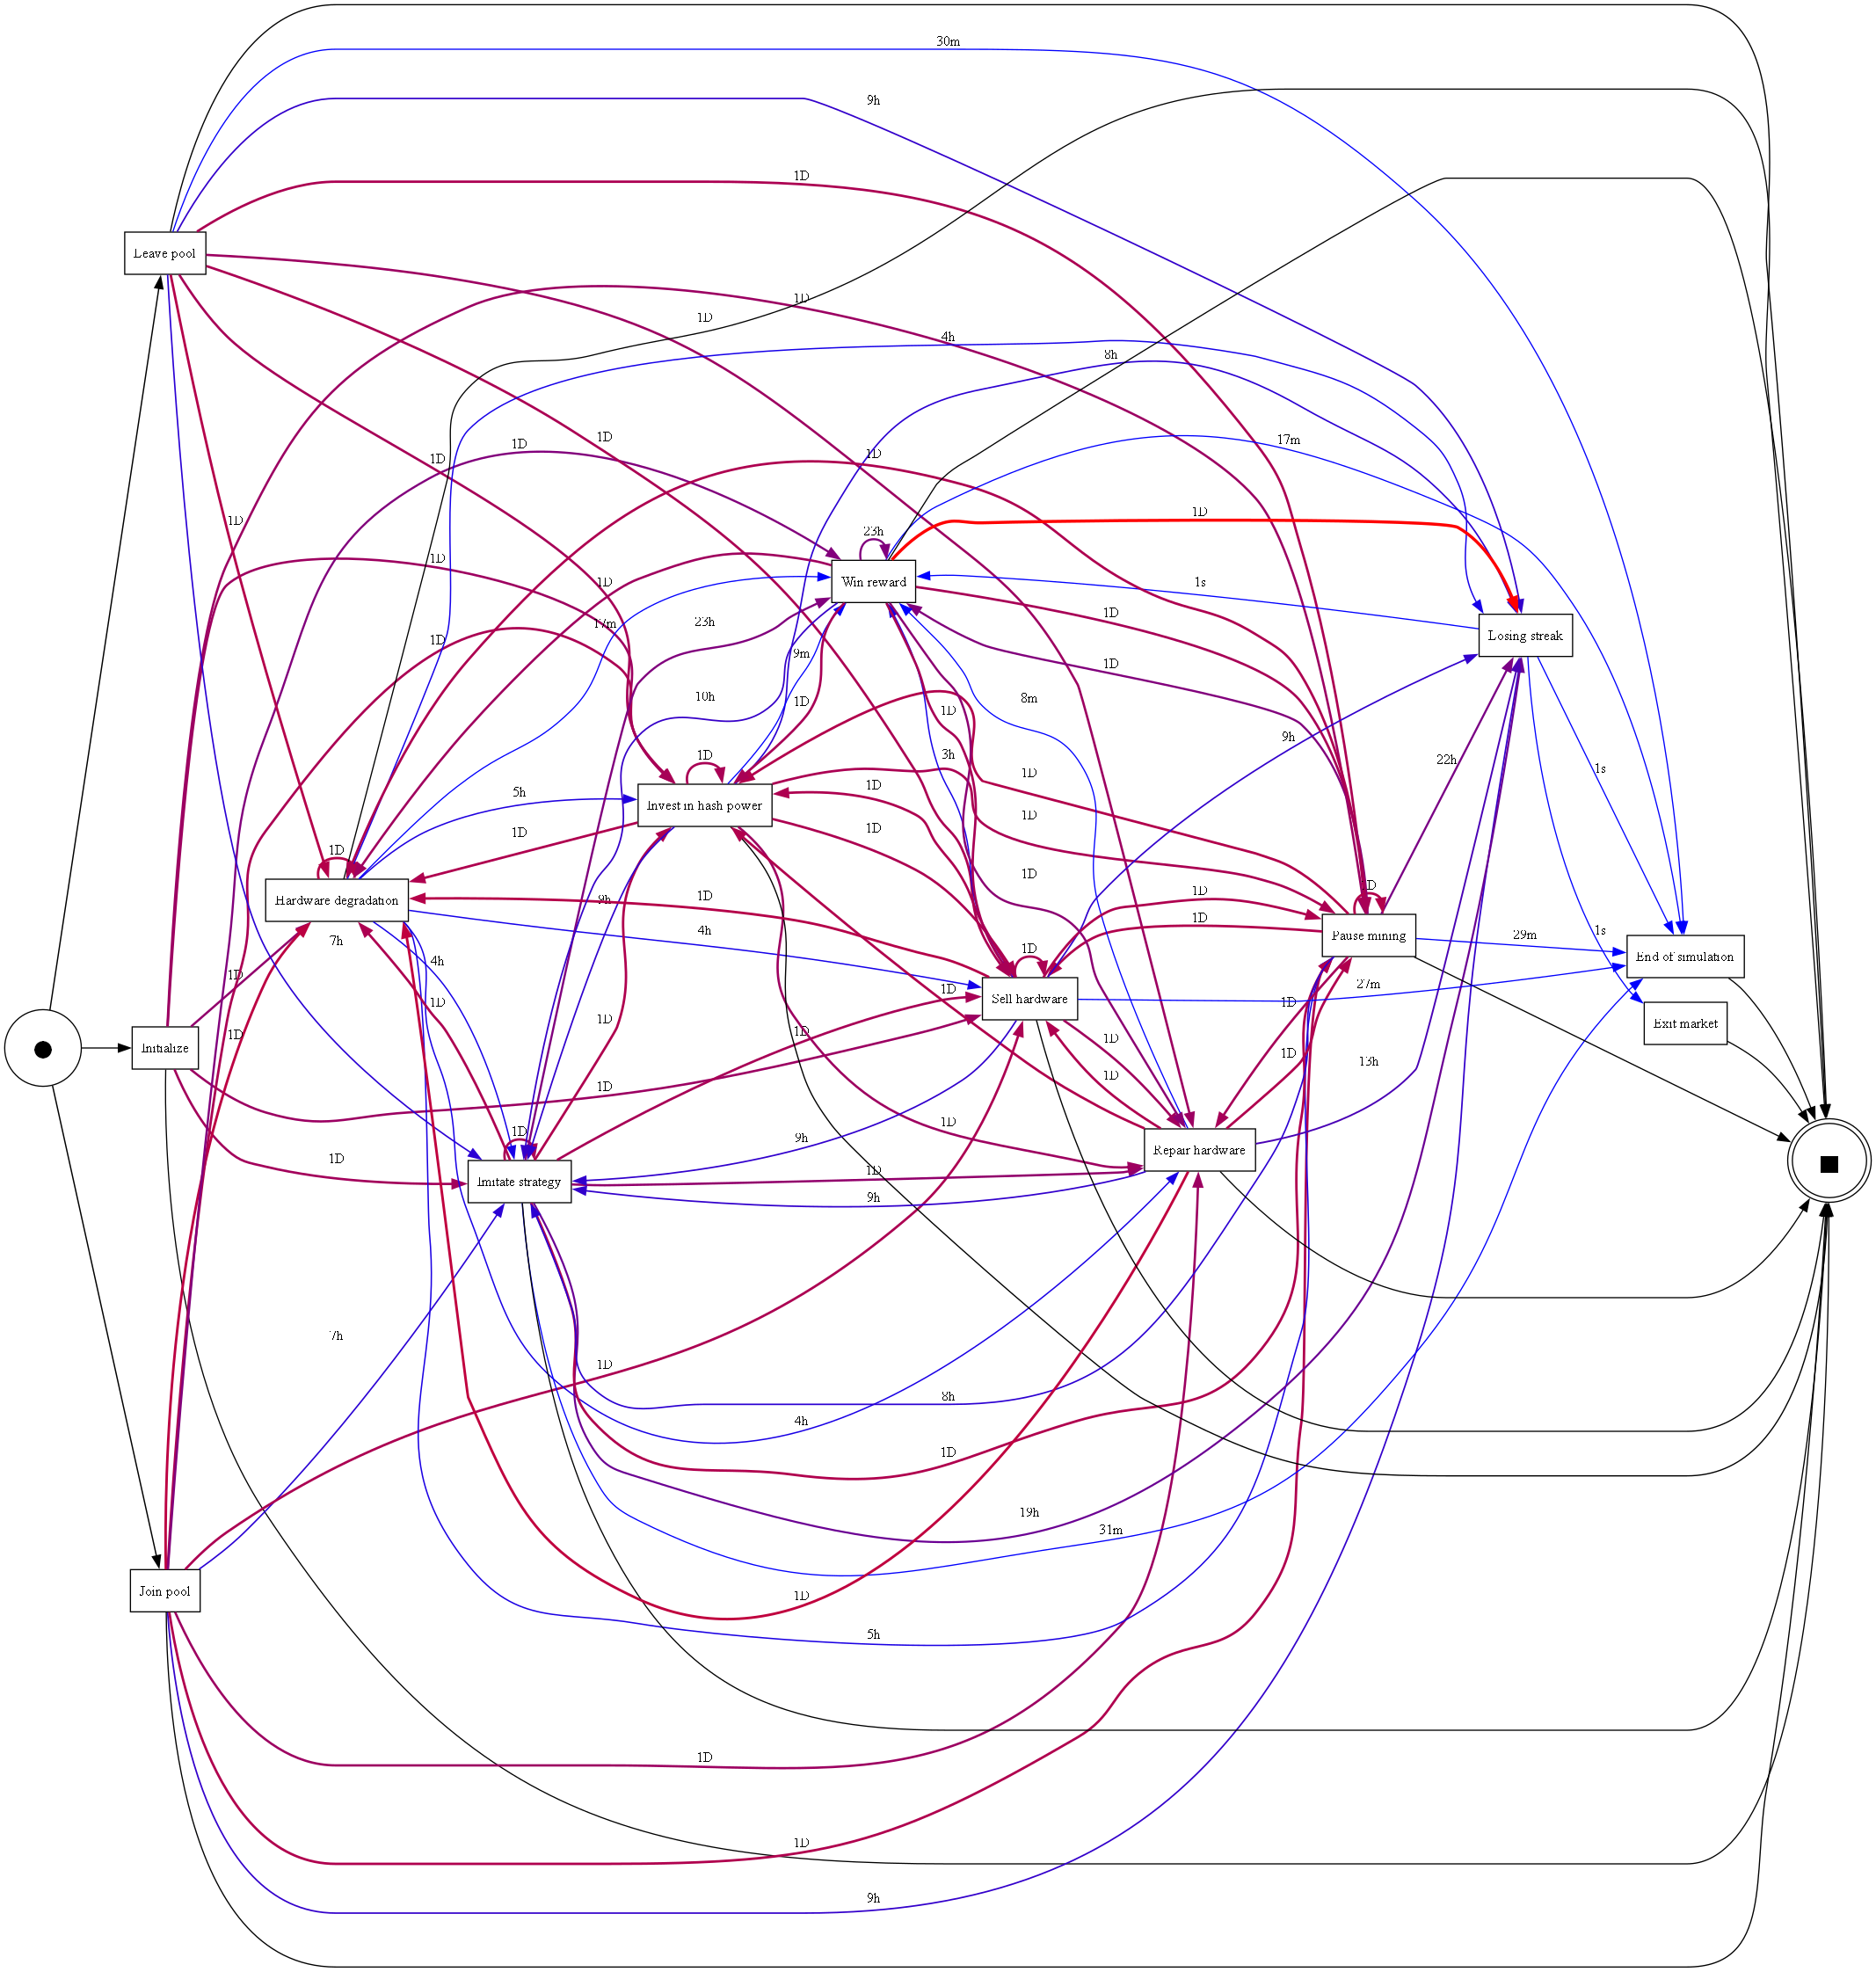

In [28]:
# Discover a Performance DFG to find time bottlenecks
dfg_perf, start_p, end_p = pm4py.discover_performance_dfg(clean_log)
pm4py.view_performance_dfg(dfg_perf, start_p, end_p)

In [29]:
import pm4py

# 1. Define the "Normative Model" (e.g., the top 5 most common "happy paths")
# This represents the expected protocol of a rational miner.
normative_log = pm4py.filter_variants_top_k(clean_log, 5) 
net, im, fm = pm4py.discover_petri_net_inductive(normative_log)

# 2. Replay the FULL, chaotic simulation log against this clean model
# This tests if the emergent behavior matches the designed expectations
fitness_dict = pm4py.fitness_token_based_replay(clean_log, net, im, fm)

print("--- CONFORMANCE CHECKING RESULTS ---")
print(f"Overall Log Fitness: {fitness_dict['log_fitness']:.2%}")
print(f"Percentage of Perfectly Fit Traces: {fitness_dict['perc_fit_traces']:.2%}")

# 3. Diagnose the deviations (Where did agents act "irrationally"?)
replayed_traces = pm4py.conformance_diagnostics_token_based_replay(clean_log, net, im, fm)

deviations = 0
for trace in replayed_traces:
    if not trace['trace_is_fit']:
        deviations += 1

print(f"Total traces containing deviations: {deviations}")

replaying log with TBR, completed traces ::   0%|          | 0/4941 [00:00<?, ?it/s]

--- CONFORMANCE CHECKING RESULTS ---
Overall Log Fitness: 87.39%
Percentage of Perfectly Fit Traces: 6117.15%


replaying log with TBR, completed traces ::   0%|          | 0/4941 [00:00<?, ?it/s]

Total traces containing deviations: 9751


In [30]:
import pandas as pd

# Convert the event log to a DataFrame
df = pm4py.convert_to_dataframe(clean_log)

print("--- AVAILABLE COLUMNS IN YOUR LOG ---")
print([col for col in df.columns])
print("\n" + "="*40 + "\n")

# Automatically detect the correct column names by matching substrings
grid_col = next((c for c in df.columns if 'grid' in c.lower()), None)
capital_col = next((c for c in df.columns if 'capital' in c.lower()), None)

# 1. Market Exits by Energy Grid
if grid_col:
    exit_events = df[df['concept:name'] == 'Exit market']
    if not exit_events.empty:
        grid_exits = exit_events.groupby(grid_col).size()
        print("--- MARKET EXITS BY ENERGY GRID ---")
        print(grid_exits)
    else:
        print("--- MARKET EXITS BY ENERGY GRID ---")
        print("No 'Exit market' events found in this subset.")
else:
    print("Could not find an energy grid column. Check the printed list above.")

print("\n" + "="*40 + "\n")

# 2. Capital vs Pool Dynamics
if capital_col:
    pool_events = df[df['concept:name'] == 'Join pool']
    if not pool_events.empty:
        # Get unique case IDs for agents who joined pools
        pool_cases = pool_events['case:concept:name'].unique()
        
        avg_pool_capital = df[df['case:concept:name'].isin(pool_cases)][capital_col].mean()
        avg_solo_capital = df[~df['case:concept:name'].isin(pool_cases)][capital_col].mean()
        
        print("--- POOL DYNAMICS BY INITIAL CAPITAL ---")
        print(f"Avg capital of agents who joined pools: {avg_pool_capital:.2f}")
        print(f"Avg capital of strictly solo agents: {avg_solo_capital:.2f}")
    else:
        print("--- POOL DYNAMICS ---")
        print("No 'Join pool' events found in the log.")
else:
    print("Could not find a capital column. Check the printed list above.")

--- AVAILABLE COLUMNS IN YOUR LOG ---
['case_id', 'agent_id', 'cycle', 'seq', 'activity', 'reason', 'capital', 'hash_power', 'risk_tolerance', 'hardware_efficiency', 'grid', 'energy_price', 'coin_price', 'pool_id', 'status', 'paused', 'last_action', 'hash_lost', 'amount', 'hash_added', 'old_pool', 'new_pool', 'hash_sold', 'hash_repaired', 'reward', 'cost', 'profit', 'mentor_id', 'streak_length', 'streak_cost', 'timestamp', 'episode', 'case:concept:name', 'concept:name', 'time:timestamp', '@@index', '@@case_index', 'start_timestamp']


--- MARKET EXITS BY ENERGY GRID ---
grid
Grid_B_medium            2
Grid_C_cheap_volatile    1
Grid_D_high_stable       8
dtype: int64


--- POOL DYNAMICS BY INITIAL CAPITAL ---
Avg capital of agents who joined pools: 362.97
Avg capital of strictly solo agents: 364.42


## 13. Process Mining

In [31]:
import shutil

print(shutil.which("dot"))

C:\Program Files\Graphviz\bin\dot.EXE


Here, the raw pandas DataFrame is formatted into a standard event log compatible with pm4py. It also cleans the data by filtering out low-value, repetitive activities like "Continue mining" to reduce visual noise and prints the resulting reduction in log size.

In [32]:
import pm4py

# 1. Format the dataframe to be compatible with pm4py
pm4py_log = pm4py.format_dataframe(
    pm_log, 
    case_id='case_id', 
    activity_key='activity', 
    timestamp_key='timestamp'
)

# 2. Filter out spam/low-value activities (adjust this list based on your needs)
activities_to_remove = ["Continue mining"]
clean_log = pm4py.filter_event_attribute_values(
    pm4py_log, 
    "concept:name", 
    activities_to_remove, 
    level="event", 
    retain=False
)

print(f"Original log size: {len(pm4py_log)} events")
print(f"Cleaned log size: {len(clean_log)} events")

Original log size: 113445 events
Cleaned log size: 86253 events


This cell filters the log down to the top ten most frequent behavioral variants to establish a baseline. It then discovers and displays two Directly-Follows Graphs (DFGs): one showing the frequency of transitions between steps, and another showing the average performance time between them.

C:\Users\marti\AppData\Roaming\Python\Python311\site-packages\pm4py\algo\discovery\dfg\adapters\pandas\df_statistics.py:93: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[start_timestamp_key] = df[timestamp_key]


Displaying Top-K Filtered Frequency DFG...


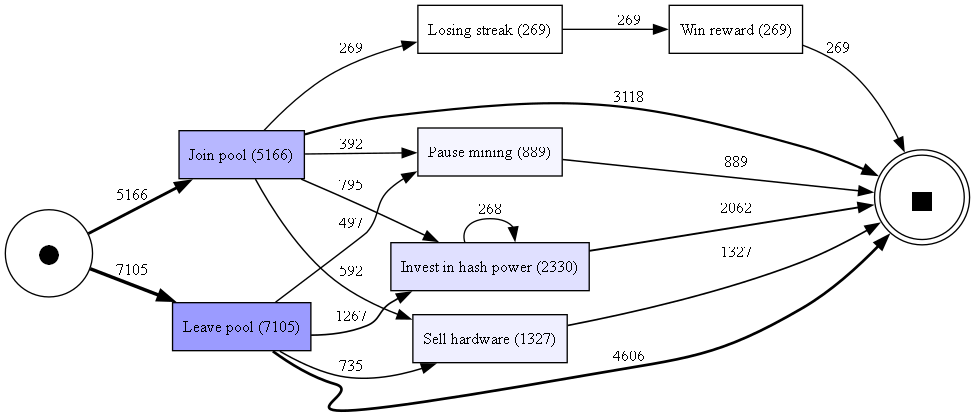

Displaying Top-K Filtered Performance DFG...


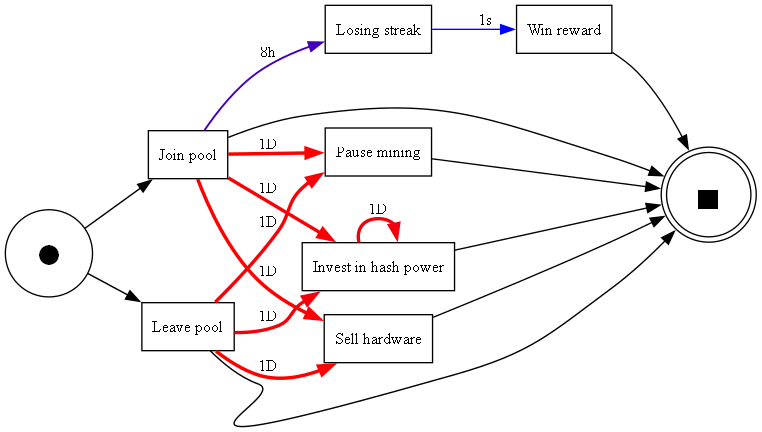

In [35]:
import pm4py

# Keep the top 10 most frequent agent behaviors
filtered_log = pm4py.filter_variants_top_k(clean_log, 10)

# 1. Discover and view Frequency DFG 
dfg, start_activities, end_activities = pm4py.discover_dfg(filtered_log)
print("Displaying Top-K Filtered Frequency DFG...")
pm4py.view_dfg(dfg, start_activities, end_activities)

# 2. Discover and view Performance DFG 
dfg_perf, start_p, end_p = pm4py.discover_performance_dfg(filtered_log)
print("Displaying Top-K Filtered Performance DFG...")
# Removed format="svg" so Jupyter can display it
pm4py.view_performance_dfg(dfg_perf, start_p, end_p)

By isolating the data to the top five most common sequences, this cell identifies the simulation's "happy path." It uses the Inductive Miner algorithm to discover and render a structurally sound Petri Net, representing the baseline expectation for rational agent behavior.

Displaying 'Happy Path' Petri Net...


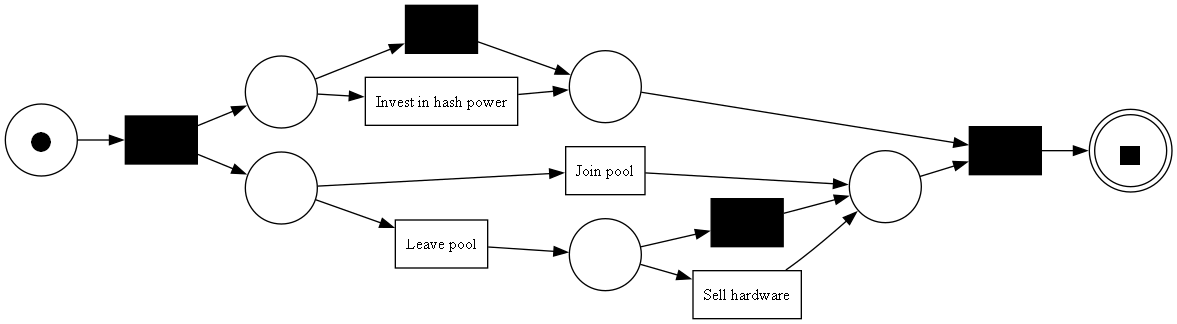

In [36]:
# 1. Filter down to the absolute most common sequences (Top 5 variants)
happy_path_log = pm4py.filter_variants_top_k(clean_log, 5) 

# 2. Discover a Petri Net using the Inductive Miner on ONLY the happy path
net, initial_marking, final_marking = pm4py.discover_petri_net_inductive(happy_path_log)

# 3. View the structurally sound, highly readable Petri Net
print("Displaying 'Happy Path' Petri Net...")
pm4py.view_petri_net(net, initial_marking, final_marking)

Using the exact same isolated "happy path" data from the previous step, this cell discovers and renders a Business Process Model and Notation (BPMN) diagram. This provides a more standardized, business-friendly visualization of the core process compared to a strict Petri Net.

Displaying 'Happy Path' BPMN Model...


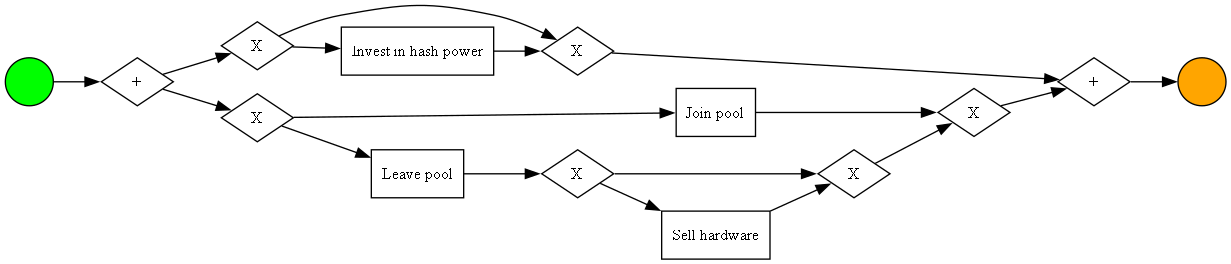

In [37]:
# Discover a BPMN model using the same isolated happy path data
bpmn_model = pm4py.discover_bpmn_inductive(happy_path_log)

# View the BPMN model
print("Displaying 'Happy Path' BPMN Model...")
pm4py.view_bpmn(bpmn_model)

This diagnostic cell splits the log into two distinct cohorts—"Losers" and "Survivors"—based on their final outcome. By applying custom frequency thresholds to trim away rare edge cases, it renders clean, comparative DFGs so you can visually analyze the differing behavioral paths between failed and successful agents.

C:\Users\marti\AppData\Roaming\Python\Python311\site-packages\pm4py\algo\discovery\dfg\adapters\pandas\df_statistics.py:93: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[start_timestamp_key] = df[timestamp_key]
C:\Users\marti\AppData\Roaming\Python\Python311\site-packages\pm4py\algo\discovery\dfg\adapters\pandas\df_statistics.py:93: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[start_timestamp_key] = df[timestamp_key]


--- TOP 10 PATHS (SURVIVORS) ---
Losing streak -> End of simulation: 978
Sell hardware -> Losing streak: 274
Invest in hash power -> Losing streak: 247
Sell hardware -> Sell hardware: 235
Sell hardware -> Invest in hash power: 226
Invest in hash power -> Sell hardware: 219
Join pool -> Losing streak: 187
Invest in hash power -> Invest in hash power: 180
Join pool -> Sell hardware: 157
Pause mining -> Losing streak: 157

--- TOP 10 PATHS (LOSERS) ---
Losing streak -> Exit market: 11
Invest in hash power -> Invest in hash power: 4
Sell hardware -> Losing streak: 4
Invest in hash power -> Imitate strategy: 3
Invest in hash power -> Sell hardware: 3
Join pool -> Invest in hash power: 3
Join pool -> Losing streak: 3
Sell hardware -> Invest in hash power: 3
Hardware degradation -> Repair hardware: 2
Invest in hash power -> Pause mining: 2


Displaying 'Exit Market' DFG (Edges > 2)...


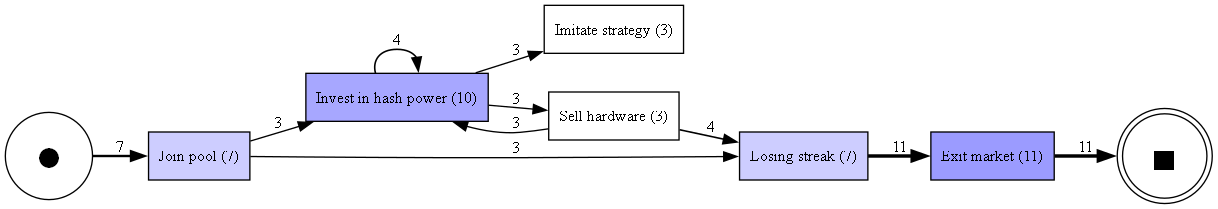

Displaying 'End of Simulation' DFG (Edges > 50)...


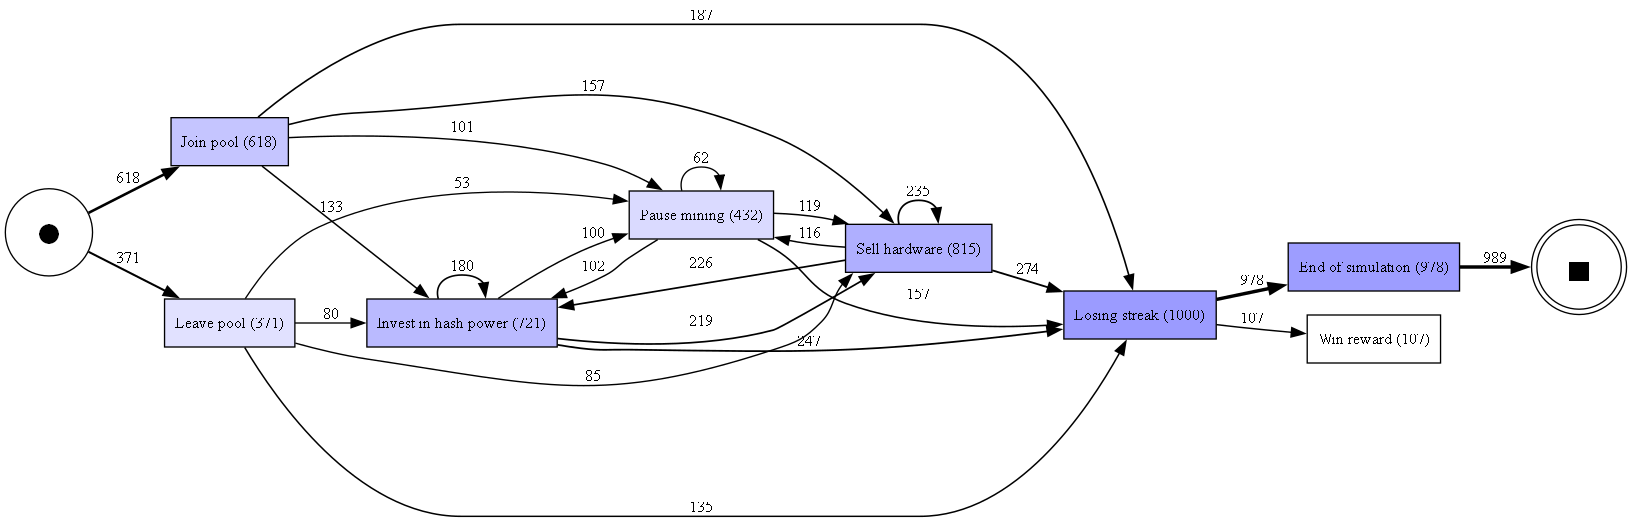

In [38]:
from collections import Counter

# 1. Split the log based on the final outcome of the case
losers_log = pm4py.filter_end_activities(clean_log, ["Exit market"])
survivors_log = pm4py.filter_end_activities(clean_log, ["End of simulation"])

# 2. Discover raw DFGs for both segments
dfg_losers, start_l, end_l = pm4py.discover_dfg(losers_log)
dfg_survivors, start_s, end_s = pm4py.discover_dfg(survivors_log)

# --- DIAGNOSTICS: Let's see the actual numbers! ---
print("--- TOP 10 PATHS (SURVIVORS) ---")
for path, count in Counter(dfg_survivors).most_common(10):
    print(f"{path[0]} -> {path[1]}: {count}")

print("\n--- TOP 10 PATHS (LOSERS) ---")
for path, count in Counter(dfg_losers).most_common(10):
    print(f"{path[0]} -> {path[1]}: {count}")
print("\n")

# --- THE FIX: MUCH LOWER THRESHOLDS ---
# Dropping this down so we catch the middle loops
THRESHOLD_LOSERS = 2 
THRESHOLD_SURVIVORS = 50 

# Filter the "Losers" DFG
dfg_l_filtered = {k: v for k, v in dfg_losers.items() if v > THRESHOLD_LOSERS}
surviving_l_nodes = set([node for path in dfg_l_filtered.keys() for node in path])
start_l_filt = {k: v for k, v in start_l.items() if k in surviving_l_nodes}
end_l_filt = {k: v for k, v in end_l.items() if k in surviving_l_nodes}

# Filter the "Survivors" DFG
dfg_s_filtered = {k: v for k, v in dfg_survivors.items() if v > THRESHOLD_SURVIVORS}
surviving_s_nodes = set([node for path in dfg_s_filtered.keys() for node in path])
start_s_filt = {k: v for k, v in start_s.items() if k in surviving_s_nodes}
end_s_filt = {k: v for k, v in end_s.items() if k in surviving_s_nodes}
# ------------------------------------------

# 3. View the 'Exit Market' (Failure) graph
if len(dfg_l_filtered) == 0:
    print(f"⚠️ THRESHOLD ERROR: {THRESHOLD_LOSERS} is too high for Losers. Lower it.")
else:
    print(f"Displaying 'Exit Market' DFG (Edges > {THRESHOLD_LOSERS})...")
    pm4py.view_dfg(dfg_l_filtered, start_l_filt, end_l_filt)

# 4. View the 'End of Simulation' (Success) graph
if len(dfg_s_filtered) == 0:
    print(f"⚠️ THRESHOLD ERROR: {THRESHOLD_SURVIVORS} is too high for Survivors. Lower it.")
else:
    print(f"Displaying 'End of Simulation' DFG (Edges > {THRESHOLD_SURVIVORS})...")
    pm4py.view_dfg(dfg_s_filtered, start_s_filt, end_s_filt)

This is a brief utility cell designed specifically to re-render the performance DFG. By intentionally omitting the format="svg" parameter, it ensures that the graph displays correctly inline without triggering rendering issues common in Jupyter Notebook environments.

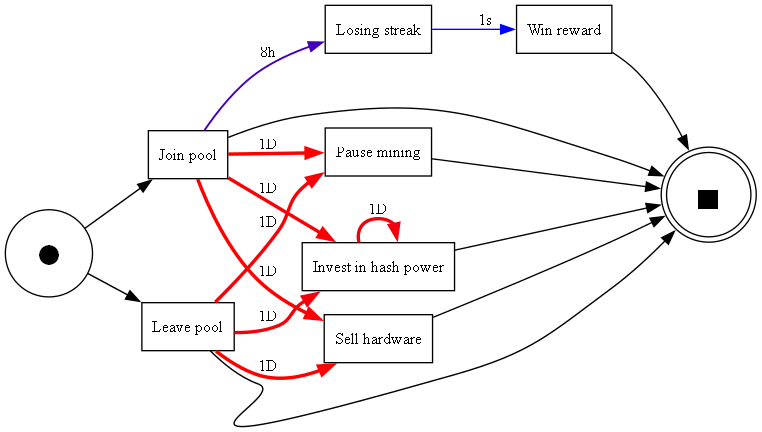

In [40]:
dfg_perf, start_p, end_p = pm4py.discover_performance_dfg(filtered_log)

# Notice how format="svg" is completely removed here:
pm4py.view_performance_dfg(dfg_perf, start_p, end_p)

This cell performs conformance checking to measure how actual agent behavior deviated from expectations. It replays the full, unfiltered simulation log against the strict "happy path" Petri Net, calculating an overall fitness score and counting exactly how many traces exhibited irrational or unexpected deviations.

In [43]:
import pm4py

# 1. Define the "Normative Model" (e.g., the top 5 most common "happy paths")
# This represents the expected protocol of a rational miner.
normative_log = pm4py.filter_variants_top_k(clean_log, 5) 
net, im, fm = pm4py.discover_petri_net_inductive(normative_log)

# 2. Replay the FULL, chaotic simulation log against this clean model
# This tests if the emergent behavior matches the designed expectations
fitness_dict = pm4py.fitness_token_based_replay(clean_log, net, im, fm)

print("--- CONFORMANCE CHECKING RESULTS ---")
print(f"Overall Log Fitness: {fitness_dict['log_fitness']:.2%}")

# FIX APPLIED HERE: Changed :.2% to :.2f%
print(f"Percentage of Perfectly Fit Traces: {fitness_dict['perc_fit_traces']:.2f}%")

# 3. Diagnose the deviations (Where did agents act "irrationally"?)
replayed_traces = pm4py.conformance_diagnostics_token_based_replay(clean_log, net, im, fm)

deviations = 0
for trace in replayed_traces:
    if not trace['trace_is_fit']:
        deviations += 1

print(f"Total traces containing deviations: {deviations}")

replaying log with TBR, completed traces ::   0%|          | 0/4941 [00:00<?, ?it/s]

--- CONFORMANCE CHECKING RESULTS ---
Overall Log Fitness: 87.39%
Percentage of Perfectly Fit Traces: 61.17%


replaying log with TBR, completed traces ::   0%|          | 0/4941 [00:00<?, ?it/s]

Total traces containing deviations: 9751


Finally, this cell converts the event log back into a Pandas DataFrame to perform traditional attribute-based analytics. It dynamically locates your specific columns to aggregate market exits by their specific energy grid and compares the average starting capital of agents who joined pools versus those who mined solo.

In [44]:
import pandas as pd

# Convert the event log to a DataFrame
df = pm4py.convert_to_dataframe(clean_log)

print("--- AVAILABLE COLUMNS IN YOUR LOG ---")
print([col for col in df.columns])
print("\n" + "="*40 + "\n")

# Automatically detect the correct column names by matching substrings
grid_col = next((c for c in df.columns if 'grid' in c.lower()), None)
capital_col = next((c for c in df.columns if 'capital' in c.lower()), None)

# 1. Market Exits by Energy Grid
if grid_col:
    exit_events = df[df['concept:name'] == 'Exit market']
    if not exit_events.empty:
        grid_exits = exit_events.groupby(grid_col).size()
        print("--- MARKET EXITS BY ENERGY GRID ---")
        print(grid_exits)
    else:
        print("--- MARKET EXITS BY ENERGY GRID ---")
        print("No 'Exit market' events found in this subset.")
else:
    print("Could not find an energy grid column. Check the printed list above.")

print("\n" + "="*40 + "\n")

# 2. Capital vs Pool Dynamics
if capital_col:
    pool_events = df[df['concept:name'] == 'Join pool']
    if not pool_events.empty:
        # Get unique case IDs for agents who joined pools
        pool_cases = pool_events['case:concept:name'].unique()
        
        avg_pool_capital = df[df['case:concept:name'].isin(pool_cases)][capital_col].mean()
        avg_solo_capital = df[~df['case:concept:name'].isin(pool_cases)][capital_col].mean()
        
        print("--- POOL DYNAMICS BY INITIAL CAPITAL ---")
        print(f"Avg capital of agents who joined pools: {avg_pool_capital:.2f}")
        print(f"Avg capital of strictly solo agents: {avg_solo_capital:.2f}")
    else:
        print("--- POOL DYNAMICS ---")
        print("No 'Join pool' events found in the log.")
else:
    print("Could not find a capital column. Check the printed list above.")

--- AVAILABLE COLUMNS IN YOUR LOG ---
['case_id', 'agent_id', 'cycle', 'seq', 'activity', 'reason', 'capital', 'hash_power', 'risk_tolerance', 'hardware_efficiency', 'grid', 'energy_price', 'coin_price', 'pool_id', 'status', 'paused', 'last_action', 'hash_lost', 'amount', 'hash_added', 'old_pool', 'new_pool', 'hash_sold', 'hash_repaired', 'reward', 'cost', 'profit', 'mentor_id', 'streak_length', 'streak_cost', 'timestamp', 'episode', 'case:concept:name', 'concept:name', 'time:timestamp', '@@index', '@@case_index']


--- MARKET EXITS BY ENERGY GRID ---
grid
Grid_B_medium            2
Grid_C_cheap_volatile    1
Grid_D_high_stable       8
dtype: int64


--- POOL DYNAMICS BY INITIAL CAPITAL ---
Avg capital of agents who joined pools: 362.97
Avg capital of strictly solo agents: 364.42


## 14. Interpretation template for your report

Use this wording if the model results are usable:

> The model is not a deterministic simulation of predefined mining strategies. Instead, it is an adaptive multi-agent system in which autonomous agents update their action preferences based on experienced outcomes and limited local information. The market environment remains simulated, but agent behaviour is decentralized and partly emergent. Process mining is then applied to the generated event log to discover which behavioural process variants emerge, such as repeated solo mining, reinvestment cycles, temporary pausing, pool formation, imitation, and market exit.

Useful research question:

> Which behavioural strategies emerge among autonomous cryptocurrency mining agents under volatile market conditions, and how can process mining reveal the dominant process variants leading to survival, growth, cooperation, or exit?